# Activity 5: DBSCAN Customer Segmentation

## MLOps Practical Lab (Module 5b)

This activity applies DBSCAN (Density-Based Spatial Clustering of Applications with Noise, a clustering algorithm that groups points packed closely together and labels isolated points as noise) to retail customer data. The work follows the MLOps (Machine Learning Operations, the practice of taking a model from raw data all the way to a saved model that can be used on new data) lifecycle phases.

### Scenario

A retail company's marketing team has collected data on 200 customers. Each customer has four behavioural measurements: annual income, spending score, age, and number of years as a customer. No segment labels exist, so the number of customer groups is not known in advance.

### Main Research Question

> "Can we discover natural customer segments without being told how many segments exist, and can we identify unusual customers that don't fit any segment?"

This is an unsupervised learning (learning from data that has no answer labels) problem. DBSCAN suits it because it does not need the number of clusters in advance, it can find groups that are not round, and it can leave unusual customers unassigned instead of forcing them into a group.

### Activity Structure

| Part | MLOps Phase | Topic |
|---|---|---|
| Part 1 | Business Understanding | Problem formulation and data audit |
| Part 2 | Data Engineering | EDA, feature selection, train/test split, scaling |
| Part 3 | Model Development | Shape diagnostic, parameter selection, DBSCAN fit |
| Part 4 | Evaluation | Silhouette, Davies-Bouldin, stability, business validation |
| Part 5 | Deployment and Serving | Saved artifacts, inference on a new customer, reusable function |

**Note on results:** The lab instructions include example outputs. Every number reported in this notebook is computed from the actual dataset used here. Where an actual result differs from the example wording in the instructions, the actual result is reported.

## Part 1: Business Understanding and Problem Formulation

*(MLOps Phase 1)*

Before DBSCAN is run, the problem needs to be defined and the data needs to be checked. This part loads the customer dataset, inspects its structure, selects the features used for clustering, and completes a data audit (a checklist review that confirms the data is complete and usable).

### 1.1 Why This Dataset

The marketing team wants to know two things:

1. Whether customers fall into natural segments (groups of customers with similar behaviour).
2. Which customers are unusual and do not fit any segment.

DBSCAN addresses both questions:

- The number of segments is not known in advance, and DBSCAN does not require it.
- Customer behaviour rarely forms neat round groups, and DBSCAN can find irregular shapes.
- Some customers may be outliers (observations far from the rest, such as test accounts, fraudulent accounts, or VIPs). DBSCAN labels these as noise (`-1`) instead of forcing them into a segment.

### 1.2 Import the Required Libraries

This step imports the data tools (`pandas`, `numpy`), the plotting tools (`matplotlib`, `seaborn`), the two clustering algorithms (`DBSCAN`, `KMeans`), the evaluation metrics used later, `NearestNeighbors` for the k-distance plot, `train_test_split` for the 80/20 split, and `joblib` for saving the finished model. `RANDOM_STATE` (a fixed seed so random steps give the same result every run) is set to 42.

In [1]:
# Part 1.2: Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    adjusted_rand_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
import joblib
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.3 Load the Customer Dataset

The lab instructions load a file called `customer.csv` from a `datasets` folder. In this project the same data is saved as `Customer3.csv` in the `Week6` folder, and this notebook is saved in the `Codes` folder. The path below is built with `os.path.join` and a relative path (a location described from the notebook's own folder instead of a full drive path), so the notebook works without hard-coding a full `D:\` location. The CSV file itself is not changed.

The `os.path.exists` check stops the notebook with a clear message if the file cannot be found.

In [2]:
# Part 1.3: Load the customer dataset
# The notebook lives in Codes/, the data lives in Week6/
DATASET_DIR = os.path.join("..", "Week6")
DATASET_FILE = "Customer3.csv"
DATASET_PATH = os.path.join(DATASET_DIR, DATASET_FILE)

# Check that the file exists before loading
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {os.path.abspath(DATASET_PATH)}\n"
        f"Current working directory: {os.getcwd()}\n"
        f"Make sure 'Customer3.csv' is inside the 'Week6' folder."
    )

print(f"Loading dataset from: {DATASET_PATH}")
df = pd.read_csv(DATASET_PATH)

print("=" * 70)
print(f"Dataset shape: {df.shape}")
print("=" * 70)
print("First five rows:")
display(df.head())
print("=" * 70)
print("Dataset info:")
df.info()
print("=" * 70)
print("Missing values:")
print(df.isnull().sum())

Loading dataset from: ..\Week6\Customer3.csv
Dataset shape: (200, 5)
First five rows:


,Customer_ID,Age,Annual_Income,Spending_Score,Years_Customer
0,1,23,25,81,1
1,2,24,26,77,1
2,3,25,27,85,2
3,4,26,28,79,2
4,5,27,29,83,2


Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Customer_ID     200 non-null    int64
 1   Age             200 non-null    int64
 2   Annual_Income   200 non-null    int64
 3   Spending_Score  200 non-null    int64
 4   Years_Customer  200 non-null    int64
dtypes: int64(5)
memory usage: 7.9 KB
Missing values:
Customer_ID       0
Age               0
Annual_Income     0
Spending_Score    0
Years_Customer    0
dtype: int64


### Dataset at a Glance

In [3]:
# Dataset at a glance (every value is calculated from df)
behavioural_columns = [col for col in df.columns if col != "Customer_ID"]

dataset_at_a_glance = pd.DataFrame({
    "Measure": [
        "Customers (rows)",
        "Raw columns",
        "Clustering features (all columns except Customer_ID)",
        "Total missing values",
        "Duplicate rows",
        "Unique Customer_ID values",
    ],
    "Value": [
        str(df.shape[0]),
        str(df.shape[1]),
        str(len(behavioural_columns)),
        str(int(df.isnull().sum().sum())),
        str(int(df.duplicated().sum())),
        f"{df['Customer_ID'].nunique()} / {len(df)}",
    ],
})

dataset_at_a_glance

,Measure,Value
0,Customers (rows),200
1,Raw columns,5
2,Clustering features (all columns except Custom...,4
3,Total missing values,0
4,Duplicate rows,0
5,Unique Customer_ID values,200 / 200


The table below collects the same structure checks in one place. Every value is calculated from `df`; nothing is typed in by hand.

In [4]:
# Column overview built from the loaded data
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notnull().sum().values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values,
    "Role in Activity": [
        "Identifier (not used for clustering)" if col == "Customer_ID" else "Behavioural feature"
        for col in df.columns
    ],
})

column_overview

,Column,Data Type,Non-Null Count,Missing Values,Unique Values,Role in Activity
0,Customer_ID,int64,200,0,200,Identifier (not used for clustering)
1,Age,int64,200,0,56,Behavioural feature
2,Annual_Income,int64,200,0,134,Behavioural feature
3,Spending_Score,int64,200,0,87,Behavioural feature
4,Years_Customer,int64,200,0,25,Behavioural feature


### How to Read This

Each row of `df` is one customer. `Customer_ID` is a label that identifies the customer, and the other four columns are behavioural measurements. "Unique Values" shows how many different values appear in each column. `Customer_ID` has 200 unique values because every customer has their own ID.

### What the Output Shows

- The dataset has 200 rows (customers) and 5 columns.
- All five columns are stored as integers (`int64`).
- There are no missing values in any column.

### 1.4 Select Features for Clustering

Four features (the measurable pieces of information the algorithm is allowed to use) are selected, following the lab instructions: `Annual_Income`, `Spending_Score`, `Age`, and `Years_Customer`. They are stored in `X`.

`Customer_ID` is excluded. It is an identifier, not a behavioural measurement. DBSCAN groups customers by distance, so including an ID number would make two customers with identical behaviour look "far apart" just because their ID numbers differ.

Descriptive statistics (a quick number summary of each column, such as the average, spread, smallest, and largest values) are shown for the four selected features.

#### What Goes Into DBSCAN?

| Column | Plain-Language Meaning | Used in DBSCAN? |
|---|---|---|
| `Annual_Income` | How much the customer earns per year, in thousands of dollars (k$) | Yes |
| `Spending_Score` | A score from 1 to 100 rating the customer's spending behaviour (higher means more spending) | Yes |
| `Age` | The customer's age in years | Yes |
| `Years_Customer` | How many years the person has been a customer | Yes |
| `Customer_ID` | A number that identifies each customer | **No, excluded** (only an identifier, not a behaviour) |

In [5]:
# Part 1.4: Select features
features = ['Annual_Income', 'Spending_Score', 'Age', 'Years_Customer']
X = df[features].copy()

print("Selected features:", features)
print("X shape:", X.shape)
print("=" * 70)
print("Descriptive statistics:")
display(X.describe())

Selected features: ['Annual_Income', 'Spending_Score', 'Age', 'Years_Customer']
X shape: (200, 4)
Descriptive statistics:


,Annual_Income,Spending_Score,Age,Years_Customer
count,200.000000,200.000000,200.000000,200.000000
mean,245.855000,53.545000,42.125000,10.080000
std,685.563161,30.396012,14.581925,5.920206
min,8.000000,1.000000,18.000000,1.000000
25%,45.000000,25.000000,29.000000,5.000000
50%,80.500000,51.000000,40.000000,9.000000
75%,120.250000,85.000000,54.000000,14.000000
max,5000.000000,99.000000,75.000000,25.000000


The full descriptive statistics above are kept as evidence. The table below shows the most useful values in a simpler form.

In [6]:
# Simplified summary of the four clustering features
feature_summary = pd.DataFrame({
    "Feature": features,
    "Mean": X.mean().round(2).values,
    "Median": X.median().round(2).values,
    "Minimum": X.min().values,
    "Maximum": X.max().values,
})
feature_summary

,Feature,Mean,Median,Minimum,Maximum
0,Annual_Income,245.86,80.5,8,5000
1,Spending_Score,53.54,51.0,1,99
2,Age,42.12,40.0,18,75
3,Years_Customer,10.08,9.0,1,25


### Comparison With the Lab's Example Output

The lab instructions print example descriptive statistics for `customer.csv`. The table below places the lab's example values next to the values computed from `Customer3.csv`, to confirm that the same dataset is being used. The "Lab Example" column is typed in from the instructions; the "Actual" column is calculated from `X`.

In [7]:
# Reference values typed from the lab's example output (Part 1.4)
lab_example = {
    ("Annual_Income", "mean"): 245.855,  ("Annual_Income", "std"): 685.563161,
    ("Annual_Income", "min"): 8.0,       ("Annual_Income", "max"): 5000.0,
    ("Spending_Score", "mean"): 53.545,  ("Spending_Score", "std"): 30.396012,
    ("Spending_Score", "min"): 1.0,      ("Spending_Score", "max"): 99.0,
    ("Age", "mean"): 42.125,             ("Age", "std"): 14.581925,
    ("Age", "min"): 18.0,                ("Age", "max"): 75.0,
    ("Years_Customer", "mean"): 10.08,   ("Years_Customer", "std"): 5.920206,
    ("Years_Customer", "min"): 1.0,      ("Years_Customer", "max"): 25.0,
}

actual_stats = X.describe()
rows = []
for (feature, stat), example_value in lab_example.items():
    actual_value = actual_stats.loc[stat, feature]
    rows.append({
        "Feature": feature,
        "Statistic": stat,
        "Lab Example": round(example_value, 3),
        "Actual": round(actual_value, 3),
        "Match": "Yes" if np.isclose(actual_value, example_value, atol=1e-4) else "No",
    })

stats_comparison = pd.DataFrame(rows)
print(f"Statistics matching the lab example: "
      f"{(stats_comparison['Match'] == 'Yes').sum()} of {len(stats_comparison)}")
stats_comparison

Statistics matching the lab example: 16 of 16


,Feature,Statistic,Lab Example,Actual,Match
0,Annual_Income,mean,245.855,245.855,Yes
1,Annual_Income,std,685.563,685.563,Yes
2,Annual_Income,min,8.000,8.000,Yes
3,Annual_Income,max,5000.000,5000.000,Yes
4,Spending_Score,mean,53.545,53.545,Yes
5,Spending_Score,std,30.396,30.396,Yes
6,Spending_Score,min,1.000,1.000,Yes
7,Spending_Score,max,99.000,99.000,Yes
8,Age,mean,42.125,42.125,Yes
9,Age,std,14.582,14.582,Yes


### What the Output Shows

- `X` has 200 rows and 4 columns, one column per selected feature.
- Every mean, standard deviation (how spread out the values are around the average), minimum, and maximum matches the lab's example output, so `Customer3.csv` is the same dataset as the lab's `customer.csv`.
- `Annual_Income` ranges from 8 to 5000 with a median of 80.5, while the other three features have much smaller ranges. This difference in scale is handled later by feature scaling in Part 2.6.

### 1.5 Data Audit Summary

The audit confirms the number of observations (rows, one per customer), the number of features, missing values per feature, and data types. DBSCAN cannot handle missing values (`NaN`), so this check must pass before modelling.

*Note: the lab instructions print this code block twice by mistake. It is included once here.*

In [8]:
# Part 1.5: Data audit summary
print("=" * 70)
print("PART 1: DATA AUDIT")
print("=" * 70)
print(f"Number of observations: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Feature names: {features}")
print("\nMissing values per feature:")
print(X.isnull().sum())
print("\nData types:")
print(X.dtypes)
print("\nPart 1 data audit complete.")

PART 1: DATA AUDIT
Number of observations: 200
Number of features: 4
Feature names: ['Annual_Income', 'Spending_Score', 'Age', 'Years_Customer']

Missing values per feature:
Annual_Income     0
Spending_Score    0
Age               0
Years_Customer    0
dtype: int64

Data types:
Annual_Income     int64
Spending_Score    int64
Age               int64
Years_Customer    int64
dtype: object

Part 1 data audit complete.


In [9]:
# Audit checklist built from the data (each result is calculated, not typed in)
audit_checklist = pd.DataFrame({
    "Check": [
        "Number of observations",
        "Number of features selected",
        "Total missing values in X",
        "All features numeric",
        "Duplicate customer rows",
        "Customer_ID values unique",
    ],
    "Result": [
        X.shape[0],
        X.shape[1],
        int(X.isnull().sum().sum()),
        "Yes" if all(pd.api.types.is_numeric_dtype(X[c]) for c in features) else "No",
        int(df.duplicated().sum()),
        "Yes" if df["Customer_ID"].is_unique else "No",
    ],
})

audit_checklist

,Check,Result
0,Number of observations,200
1,Number of features selected,4
2,Total missing values in X,0
3,All features numeric,Yes
4,Duplicate customer rows,0
5,Customer_ID values unique,Yes


### What the Output Shows

- 200 observations and 4 features are ready for the next phase.
- There are no missing values, so no imputation (filling in missing values with estimates) is needed.
- All four features are numeric, which DBSCAN requires because it calculates distances.
- There are no duplicate rows, and every `Customer_ID` is unique.

### Part 1 Checkpoint

| Variable | What It Is |
|---|---|
| `df` | Full customer DataFrame (a table with labelled rows and columns) (200 × 5) |
| `X` | Selected features (200 × 4) |
| `features` | List of the four feature names |

## Part 2: Data Engineering and Preparation

*(MLOps Phase 2)*

This part explores the data, splits it into training and test sets, and scales the features. Every value reported here is calculated from `Customer3.csv`.

### 2.1 Histograms: Understanding Distributions

A histogram (a bar chart that groups values into ranges, called bins, and counts how many customers fall into each range) shows the shape of each feature on its own.

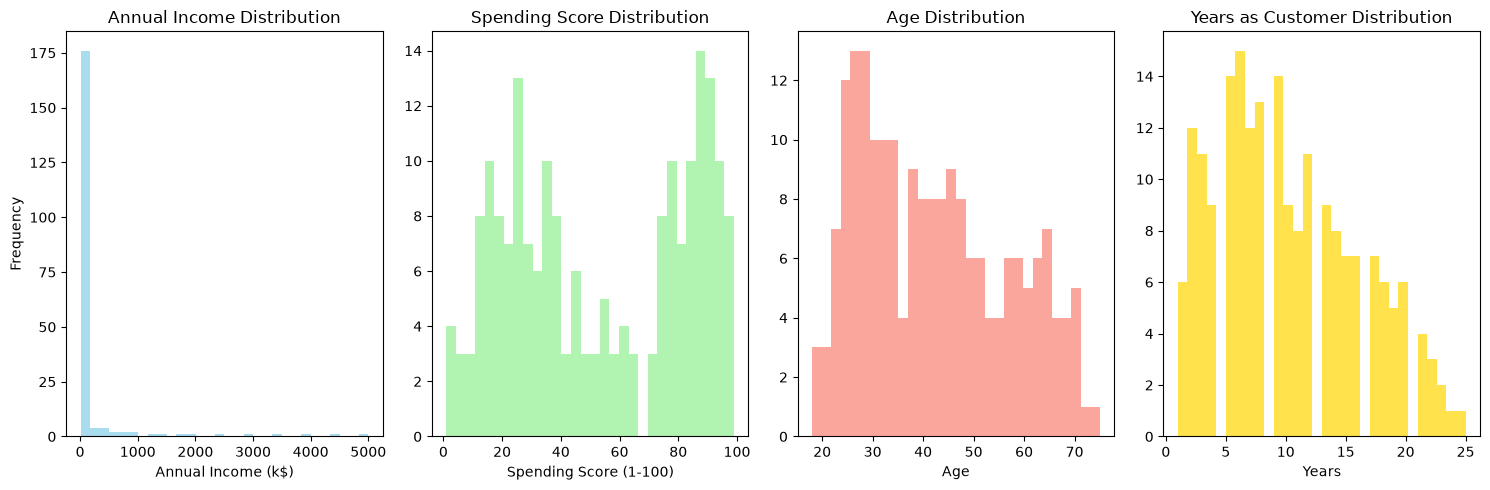

In [10]:
# Part 2.1: Histograms for each feature
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.hist(X['Annual_Income'], bins=30, alpha=0.7, color='skyblue')
plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Frequency')

plt.subplot(1, 4, 2)
plt.hist(X['Spending_Score'], bins=30, alpha=0.7, color='lightgreen')
plt.title('Spending Score Distribution')
plt.xlabel('Spending Score (1-100)')

plt.subplot(1, 4, 3)
plt.hist(X['Age'], bins=30, alpha=0.7, color='salmon')
plt.title('Age Distribution')
plt.xlabel('Age')

plt.subplot(1, 4, 4)
plt.hist(X['Years_Customer'], bins=30, alpha=0.7, color='gold')
plt.title('Years as Customer Distribution')
plt.xlabel('Years')

plt.tight_layout()
plt.show()

#### Additional Readability View: Annual Income Zoomed to 0 to 250

This is an extra view, not a replacement for the required histogram above. In the full-range histogram, a small number of very high incomes stretch the x-axis up to 5000, so most customers are squeezed into the first bar. The histogram below shows only incomes below 250 so the main customer distribution is easier to see.

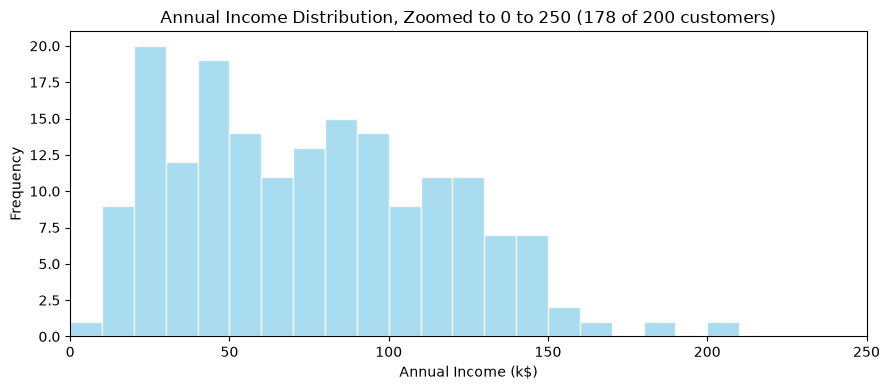

Customers with Annual_Income below 250: 178 of 200 (89.0%)
Customers with Annual_Income of 250 or more (not shown above): 22 (range 250 to 5000)


In [11]:
# Additional readability view: Annual Income below 250 only
ZOOM_LIMIT = 250
income_zoom = X.loc[X['Annual_Income'] < ZOOM_LIMIT, 'Annual_Income']
n_zoom = len(income_zoom)
n_above = len(X) - n_zoom

plt.figure(figsize=(9, 4))
plt.hist(income_zoom, bins=25, range=(0, ZOOM_LIMIT), alpha=0.7, color='skyblue', edgecolor='white')
plt.title(f'Annual Income Distribution, Zoomed to 0 to {ZOOM_LIMIT} ({n_zoom} of {len(X)} customers)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Frequency')
plt.xlim(0, ZOOM_LIMIT)
plt.tight_layout()
plt.show()

print(f"Customers with Annual_Income below {ZOOM_LIMIT}: {n_zoom} of {len(X)} ({n_zoom / len(X) * 100:.1f}%)")
print(f"Customers with Annual_Income of {ZOOM_LIMIT} or more (not shown above): {n_above} "
      f"(range {X.loc[X['Annual_Income'] >= ZOOM_LIMIT, 'Annual_Income'].min()} "
      f"to {X['Annual_Income'].max()})")

**Note:** 178 of the 200 customers have an Annual_Income below 250. The remaining 22 customers have incomes from 250 to 5000, and these few very high values are what stretch the x-axis of the full-range histogram.

The table below adds numeric evidence for each histogram:

- **Skewness** (a number that measures how lopsided a distribution is; 0 means balanced, a positive value means a long tail to the right, a negative value means a long tail to the left). A common guide: below 0.5 in size is approximately symmetric, 0.5 to 1 is moderately skewed, and above 1 is strongly skewed.
- **Mean vs median** (the average vs the middle value). A mean much larger than the median is a sign of a long right tail.
- **IQR outliers** (values beyond 1.5 × the interquartile range, the spread of the middle 50% of values, from the 25th or 75th percentile). This is a standard rule for flagging unusually low or high values.

In [12]:
# Numeric evidence for each distribution (calculated from X)
def skew_guide(s):
    s = abs(s)
    if s < 0.5:
        return "Approximately symmetric"
    elif s <= 1:
        return "Moderately skewed"
    return "Strongly skewed"

dist_rows = []
for col in features:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((X[col] < lower) | (X[col] > upper)).sum())
    skew = X[col].skew()
    dist_rows.append({
        "Feature": col,
        "Skewness": round(skew, 2),
        "Skew Guide": skew_guide(skew),
        "Mean": round(X[col].mean(), 2),
        "Median": round(X[col].median(), 2),
        "Min": X[col].min(),
        "Max": X[col].max(),
        "IQR Upper Fence": round(upper, 2),
        "IQR Outliers": n_out,
        "IQR Outliers (%)": f"{n_out / len(X) * 100:.1f}%",
    })

distribution_summary = pd.DataFrame(dist_rows)
distribution_summary

,Feature,Skewness,Skew Guide,Mean,Median,Min,Max,IQR Upper Fence,IQR Outliers,IQR Outliers (%)
0,Annual_Income,4.98,Strongly skewed,245.86,80.5,8,5000,233.12,22,11.0%
1,Spending_Score,-0.01,Approximately symmetric,53.54,51.0,1,99,175.00,0,0.0%
2,Age,0.38,Approximately symmetric,42.12,40.0,18,75,91.50,0,0.0%
3,Years_Customer,0.45,Approximately symmetric,10.08,9.0,1,25,27.50,0,0.0%


### What the Output Shows

- **Annual_Income** has a skewness of about 4.98, a mean (245.86) about three times its median (80.5), and a maximum of 5000. 22 customers (11.0%) are above the IQR upper fence of about 233. In the histogram almost every customer falls into the first bar because the few very large incomes stretch the axis.
- **Spending_Score** has a skewness of about -0.01, and its mean and median are close (53.5 and 51.0). The histogram has two main peaks, one around 15 to 40 and one around 75 to 95, with fewer customers in between.
- **Age** (skewness about 0.38) and **Years_Customer** (skewness about 0.45) have slightly larger means than medians. Neither has IQR outliers.

**Difference from the lab's example wording:** the lab describes Annual Income as having a "slight right skew". The calculated skewness of about 4.98 is well above 1, which is strongly skewed by the common guide. The lab describes Spending Score as "roughly uniform"; the histogram shows two peaks instead of an even spread. The lab also describes Age and Years_Customer as right-skewed; their calculated skewness values are below 0.5.

### 2.2 Correlation Heatmap: Checking for Redundancy

A correlation (a number from -1 to +1 showing how strongly two features move together; values near +1 or -1 mean a strong relationship, values near 0 mean little or no linear relationship) is calculated for every pair of features. The heatmap (a grid where colour shows the size of each value) displays them all at once.

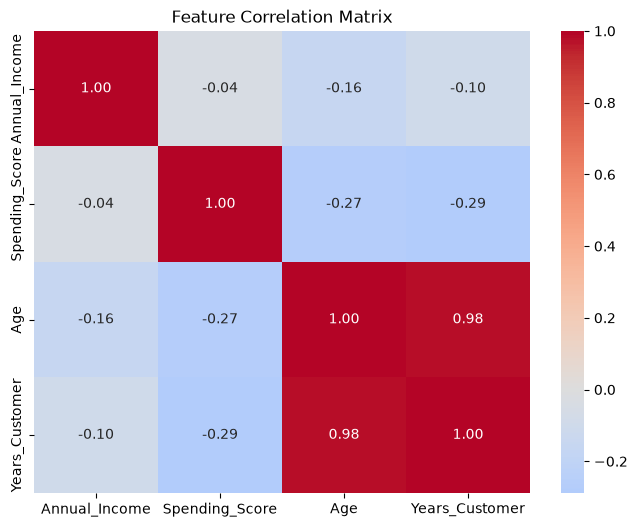

In [13]:
# Part 2.2: Correlation heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

In [14]:
# Every feature pair, sorted from strongest to weakest relationship
def corr_guide(r):
    r = abs(r)
    if r >= 0.7:
        return "Strong"
    elif r >= 0.3:
        return "Moderate"
    return "Weak"

pair_rows = []
for i, f1 in enumerate(features):
    for f2 in features[i + 1:]:
        r = correlation_matrix.loc[f1, f2]
        pair_rows.append({
            "Feature Pair": f"{f1} vs {f2}",
            "Correlation (r)": round(r, 3),
            "Direction": "Positive" if r > 0 else "Negative",
            "Strength Guide": corr_guide(r),
        })

correlation_pairs = (
    pd.DataFrame(pair_rows)
    .assign(_abs=lambda d: d["Correlation (r)"].abs())
    .sort_values("_abs", ascending=False)
    .drop(columns="_abs")
    .reset_index(drop=True)
)
correlation_pairs

,Feature Pair,Correlation (r),Direction,Strength Guide
0,Age vs Years_Customer,0.979,Positive,Strong
1,Spending_Score vs Years_Customer,-0.288,Negative,Weak
2,Spending_Score vs Age,-0.272,Negative,Weak
3,Annual_Income vs Age,-0.157,Negative,Weak
4,Annual_Income vs Years_Customer,-0.099,Negative,Weak
5,Annual_Income vs Spending_Score,-0.043,Negative,Weak


### What the Output Shows

- **Age vs Years_Customer: r = 0.98.** This is a very strong positive correlation: customers who are older almost always have more years as a customer, and younger customers have fewer.
- Every other pair has |r| below 0.3. The largest of these are Spending_Score vs Years_Customer (r = -0.29) and Spending_Score vs Age (r = -0.27).
- The strength guide used is the common rule: |r| below 0.3 is weak, 0.3 to 0.7 is moderate, 0.7 and above is strong.

**Difference from the lab's example wording:** the lab states that "all correlations are weak (|r| < 0.3)". That holds for five of the six pairs, but not for Age vs Years_Customer.

**Features used in the main analysis:** all four features are kept, because the assigned DBSCAN workflow is built on four features (MinPts = 2 × 4 = 8 in Part 3).

### 2.3 Scatter Plots: Looking for Natural Groups

A scatter plot (a chart with one dot per customer, placed by two feature values) shows how two features relate and whether customers bunch together. The four pairs below are the ones required by the lab.

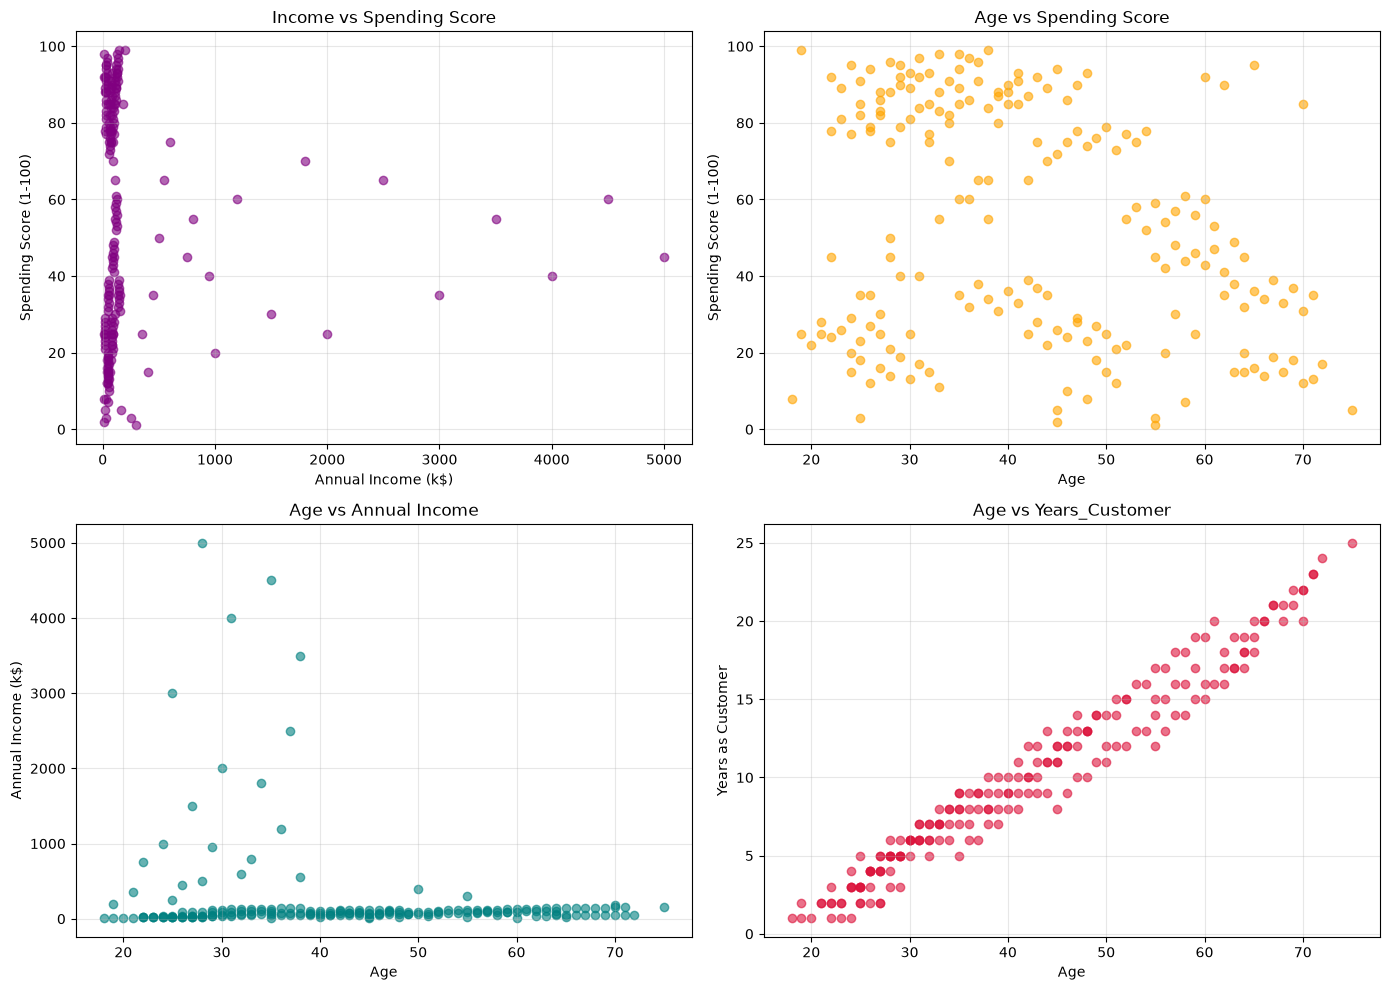

In [15]:
# Part 2.3: Scatter plots
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.scatter(X['Annual_Income'], X['Spending_Score'], alpha=0.6, color='purple')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Income vs Spending Score')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
plt.scatter(X['Age'], X['Spending_Score'], alpha=0.6, color='orange')
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.title('Age vs Spending Score')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
plt.scatter(X['Age'], X['Annual_Income'], alpha=0.6, color='teal')
plt.xlabel('Age')
plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income')
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
plt.scatter(X['Age'], X['Years_Customer'], alpha=0.6, color='crimson')
plt.xlabel('Age')
plt.ylabel('Years as Customer')
plt.title('Age vs Years_Customer')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### What the Output Shows

- **Income vs Spending Score** and **Age vs Annual Income:** most customers sit in a narrow band at the low end of the income axis (the 178 customers with incomes below 250). The 22 customers with incomes of 250 or more appear as scattered dots far to the right of or above that band.
- **Age vs Years_Customer:** the dots form a narrow rising diagonal band, which matches the r = 0.98 correlation in 2.2.
- **Age vs Spending Score:** the dots spread across the full range of ages and spending scores.

The lab also gives a verification tip: after DBSCAN is fitted in Part 3, these plots can be redrawn with each point coloured by its cluster.

### 2.4 Exploratory Data Analysis (EDA) Summary

EDA (exploratory data analysis, looking at the data with tables and charts before modelling) findings from 2.1 to 2.3 are collected below.

The lab's version of this cell prints fixed sentences (for example "Annual Income: slight right skew" and "All correlations weak"). Some of those sentences do not match this dataset, so the cell below prints the calculated evidence instead.

In [16]:
# Part 2.4: EDA evidence summary (every value is calculated, not typed in)
strong_pairs = correlation_pairs[correlation_pairs["Strength Guide"] == "Strong"]

print("=" * 70)
print("PART 2: EDA EVIDENCE SUMMARY")
print("=" * 70)

print("1. Distributions (skewness):")
for _, row in distribution_summary.iterrows():
    print(f"   - {row['Feature']}: {row['Skewness']:.2f} ({row['Skew Guide'].lower()}), "
          f"IQR outliers = {row['IQR Outliers']} ({row['IQR Outliers (%)']})")

print("\n2. Correlations:")
print(f"   - Strong pairs (|r| >= 0.7): {len(strong_pairs)}")
for _, row in strong_pairs.iterrows():
    print(f"     {row['Feature Pair']}: r = {row['Correlation (r)']:.2f}")
weak_count = (correlation_pairs["Strength Guide"] == "Weak").sum()
print(f"   - Weak pairs (|r| < 0.3): {weak_count} of {len(correlation_pairs)}")

print("\n3. Scatter plots:")
n_high_income = int((X['Annual_Income'] > distribution_summary.loc[0, 'IQR Upper Fence']).sum())
print(f"   - Customers with Annual_Income above the IQR fence: {n_high_income} "
      f"({n_high_income / len(X) * 100:.1f}%)")
print(f"   - Age vs Years_Customer forms a narrow rising band (r = "
      f"{correlation_matrix.loc['Age', 'Years_Customer']:.2f})")

print("\n4. Features kept for the main analysis:", features)
print("\nEDA complete.")

PART 2: EDA EVIDENCE SUMMARY
1. Distributions (skewness):
   - Annual_Income: 4.98 (strongly skewed), IQR outliers = 22 (11.0%)
   - Spending_Score: -0.01 (approximately symmetric), IQR outliers = 0 (0.0%)
   - Age: 0.38 (approximately symmetric), IQR outliers = 0 (0.0%)
   - Years_Customer: 0.45 (approximately symmetric), IQR outliers = 0 (0.0%)

2. Correlations:
   - Strong pairs (|r| >= 0.7): 1
     Age vs Years_Customer: r = 0.98
   - Weak pairs (|r| < 0.3): 5 of 6

3. Scatter plots:
   - Customers with Annual_Income above the IQR fence: 22 (11.0%)
   - Age vs Years_Customer forms a narrow rising band (r = 0.98)

4. Features kept for the main analysis: ['Annual_Income', 'Spending_Score', 'Age', 'Years_Customer']

EDA complete.


The data has some very high annual income values that stand out from most of the customers and could become outliers. Spending scores also seem to have some denser areas instead of one completely even distribution. Age and Years_Customer are very strongly related at about r = 0.98, so they contain a lot of overlapping information. The scatter plots do not show simple round groups and there are some isolated points, so I think DBSCAN makes sense to test because it can find irregular groups and identify customers that do not fit into a cluster.

### 2.5 Train / Test Split: 80 / 20

The data is split into two parts:

- **Training set (80%, 160 customers):** used to fit the scaler and fit DBSCAN. Every cluster, profile, and score in Parts 3 and 4 is calculated on this set.
- **Test set (20%, 40 customers):** held out completely. It is not used for training, choosing parameters, or evaluation. It is used only in Part 5 to simulate a new, unseen customer arriving at the deployed model.

`df` is split alongside `X` so that each customer's `Customer_ID` can still be looked up later. `random_state=RANDOM_STATE` makes the split the same every time the notebook runs.

**Why 80/20 and not a three-way split (train/validation/test):** a validation set (a held-out set used to compare different parameter settings) is used in supervised learning to tune hyperparameters (settings chosen before training) against known answers. DBSCAN is unsupervised and has no answers to tune against. Its parameters, ε (eps) and MinPts, are read from the k-distance plot of the training data in Part 3, so a validation set would have nothing to compare. The test set is still needed so the deployment test in Part 5 uses a customer the model has never seen.

In [17]:
# Part 2.5: Two-way split (80 / 20)
X_train, X_test, df_train, df_test = train_test_split(
    X, df,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)
print(f"Training set: {X_train.shape[0]} customers (80%)")
print(f"Test set: {X_test.shape[0]} customers (20%)")
print("\nSplit complete.")

TRAIN / TEST SPLIT
Training set: 160 customers (80%)
Test set: 40 customers (20%)

Split complete.


In [18]:
# Split sizes with percentages, plus how the 22 high-income customers were divided
income_fence = distribution_summary.loc[0, "IQR Upper Fence"]
split_summary = pd.DataFrame({
    "Set": ["Training", "Test", "Total"],
    "Customers": [len(X_train), len(X_test), len(X)],
    "Percentage": [f"{len(X_train) / len(X) * 100:.0f}%",
                   f"{len(X_test) / len(X) * 100:.0f}%", "100%"],
    "Annual_Income Above IQR Fence": [
        int((X_train["Annual_Income"] > income_fence).sum()),
        int((X_test["Annual_Income"] > income_fence).sum()),
        int((X["Annual_Income"] > income_fence).sum()),
    ],
})
split_summary

,Set,Customers,Percentage,Annual_Income Above IQR Fence
0,Training,160,80%,17
1,Test,40,20%,5
2,Total,200,100%,22


### 2.6 Feature Scaling: Fit on Training Data Only

`StandardScaler` (rescales each feature so its mean is 0 and its standard deviation is 1) puts all four features on the same scale. This matters for DBSCAN because it measures Euclidean distance (straight-line distance between two points). Without scaling, Annual_Income (values up to 5000) would dominate Age (values up to 75) in every distance calculation.

**Fit on train only:** the scaler learns each feature's mean and standard deviation from the training set only (`fit_transform`). The test set is transformed with those same training values (`transform`). Fitting on all the data would let information from the test set leak (data leakage, when information the model should not see influences training) into the model.

In [19]:
# Part 2.6: Standardize the features (fit on training data only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)   # transform, not fit

print("=" * 70)
print("PART 2: FEATURE SCALING")
print("=" * 70)
print("Original X_train shape:", X_train.shape)
print("Scaled X_train_scaled shape:", X_train_scaled.shape)
print("\nScaled feature means (should be ~0):")
print(X_train_scaled.mean(axis=0).round(4))
print("\nScaled feature standard deviations (should be 1):")
print(X_train_scaled.std(axis=0).round(4))
print("\nLearned parameters (must be reused for new customers):")
for i, col in enumerate(features):
    print(f"  {col}: mean = {scaler.mean_[i]:.2f}, std = {scaler.scale_[i]:.2f}")
print("\nFitted scaler stored in variable: scaler")

PART 2: FEATURE SCALING
Original X_train shape: (160, 4)
Scaled X_train_scaled shape: (160, 4)

Scaled feature means (should be ~0):
[-0.  0. -0. -0.]

Scaled feature standard deviations (should be 1):
[1. 1. 1. 1.]

Learned parameters (must be reused for new customers):
  Annual_Income: mean = 257.49, std = 734.78
  Spending_Score: mean = 53.80, std = 30.17
  Age: mean = 41.91, std = 14.15
  Years_Customer: mean = 9.96, std = 5.75

Fitted scaler stored in variable: scaler


In [20]:
# Scaling results in one table
scaling_summary = pd.DataFrame({
    "Feature": features,
    "Learned Mean (train)": scaler.mean_.round(2),
    "Learned Std (train)": scaler.scale_.round(2),
    "Scaled Train Mean": X_train_scaled.mean(axis=0).round(4) + 0.0,   # + 0.0 removes "-0.0" 
    "Scaled Train Std": X_train_scaled.std(axis=0).round(4),
    "Scaled Test Mean": X_test_scaled.mean(axis=0).round(4),
    "Scaled Test Std": X_test_scaled.std(axis=0).round(4),
})
scaling_summary

,Feature,Learned Mean (train),Learned Std (train),Scaled Train Mean,Scaled Train Std,Scaled Test Mean,Scaled Test Std
0,Annual_Income,257.49,734.78,0.0,1.0,-0.0792,0.5708
1,Spending_Score,53.80,30.17,0.0,1.0,-0.0423,1.0232
2,Age,41.91,14.15,0.0,1.0,0.0751,1.1318
3,Years_Customer,9.96,5.75,0.0,1.0,0.1076,1.1234


### How to Read This

The "Learned" columns are the values the scaler took from the training set. These exact values are saved in Part 5 and reused for every new customer. The scaled training data has a mean of 0 and a standard deviation of 1 for every feature, as expected. (A printed value of `-0.` above is a tiny rounding result and equals 0.) The scaled test data does not land exactly on 0 and 1, because it was transformed with the training values instead of its own. The largest gap is Annual_Income, with a scaled test standard deviation of about 0.57. The test-set incomes vary less than the training incomes, because most of the largest extreme values (including every income from 3000 to 5000) landed in the training set. This is the intended behaviour of fitting on the training set only.

### Part 2 Checkpoint

| Variable | What It Is |
|---|---|
| `distribution_summary` | Skewness, mean, median, and IQR outlier counts per feature |
| `correlation_matrix` | Correlation values between features |
| `correlation_pairs` | Every feature pair, sorted by strength |
| `X_train`, `X_test` | Feature splits (160 / 40) |
| `df_train`, `df_test` | Full customer rows for each split, including `Customer_ID` |
| `X_train_scaled`, `X_test_scaled` | Standardized feature splits |
| `scaler` | Fitted `StandardScaler` (used for every future transform) |

## Part 3: Model Development and Tuning

*(MLOps Phase 3, development sub-phase)*

This part checks the shape of the training data, reads the DBSCAN parameters from the k-distance plot, and then fits DBSCAN on the standardized training data.

### 3.1 Shape Diagnostic

Before DBSCAN is run, the two feature pairs the lab focuses on are plotted again, this time using the **training data only** (160 customers):

- **Pair 1:** Annual Income vs Spending Score
- **Pair 2:** Age vs Years_Customer

The purpose is to see whether the customers form round, evenly sized groups or more irregular shapes, since DBSCAN can find irregular density-based groups (groups defined by where points are packed closely together).

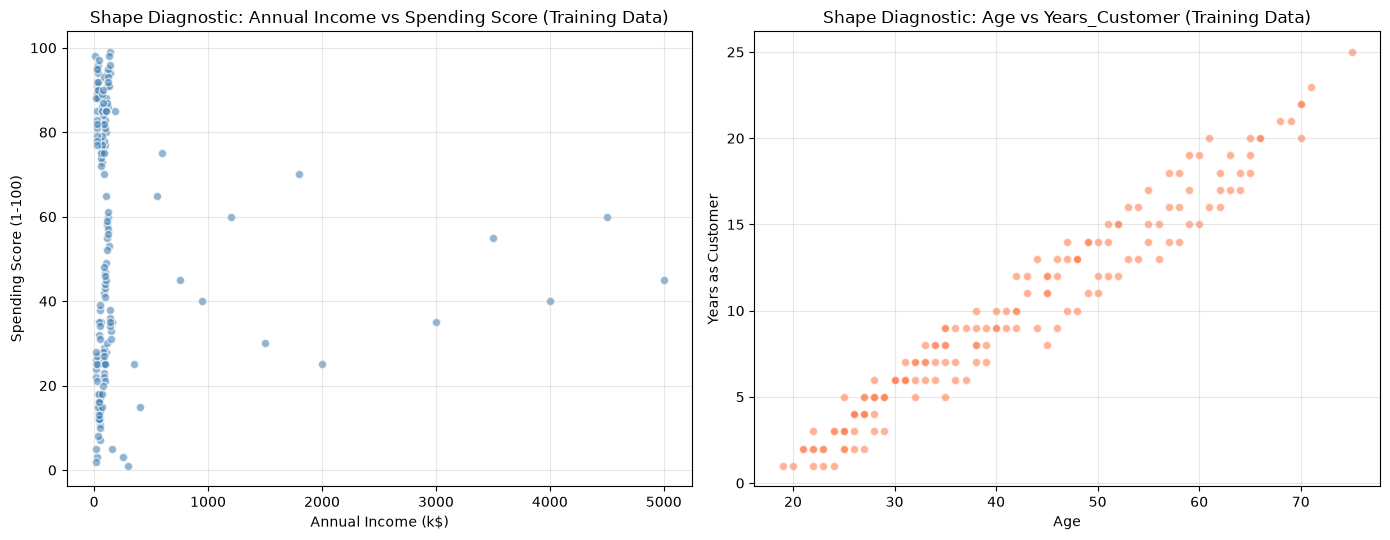

Training customers plotted: 160
Training customers with Annual_Income above the IQR fence (~233): 17 (10.6%)
Age vs Years_Customer correlation in the training data: r = 0.977


In [21]:
# Part 3.1: Shape diagnostic on the training data
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(X_train['Annual_Income'], X_train['Spending_Score'],
                alpha=0.6, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].set_title('Shape Diagnostic: Annual Income vs Spending Score (Training Data)')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X_train['Age'], X_train['Years_Customer'],
                alpha=0.6, color='coral', edgecolor='white')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Years as Customer')
axes[1].set_title('Shape Diagnostic: Age vs Years_Customer (Training Data)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

income_fence = distribution_summary.loc[0, "IQR Upper Fence"]
n_high_train = int((X_train['Annual_Income'] > income_fence).sum())
print(f"Training customers plotted: {len(X_train)}")
print(f"Training customers with Annual_Income above the IQR fence (~{income_fence:.0f}): "
      f"{n_high_train} ({n_high_train / len(X_train) * 100:.1f}%)")
print(f"Age vs Years_Customer correlation in the training data: "
      f"r = {X_train['Age'].corr(X_train['Years_Customer']):.3f}")

### What the Output Shows

- **Annual Income vs Spending Score:** most training customers sit in a narrow vertical band at the low end of the income axis, spread across the full 1 to 100 spending range. 17 training customers (10.6%) have incomes above the IQR fence and appear as isolated dots spread to the right.
- **Age vs Years_Customer:** the points form a narrow rising diagonal band. Younger customers only have low Years_Customer values, so the lower-right area of the plot is empty, which gives the band its triangular, boundary-limited shape.
- Neither plot shows clean, round, evenly sized groups.

### 3.2 k-Distance Plot: Choosing ε (epsilon)

DBSCAN needs two parameters:

- **ε (eps):** the radius around each point (how close two customers must be to count as neighbours).
- **MinPts (`min_samples`):** how many points must be inside that radius for a point to be a core point (a point in a dense area that can anchor a cluster).

The lab's rule of thumb is **MinPts = 2 × number of features**. With 4 features, MinPts = 8, so k = 8 is used for the plot. This keeps the ε read from the plot consistent with the MinPts used in DBSCAN.

For every training customer, the distance to its 8th-nearest neighbour is calculated (in standardized units). These distances are sorted from smallest to largest and plotted:

- **Left side (small distances):** customers inside dense areas.
- **Right side (large distances):** isolated customers, likely to become noise.
- **The elbow:** the bend where the curve starts rising sharply. The y-value at the elbow is the natural choice for ε.

*Note: the lab's example plot is labelled k = 5, but the lab's code and text use k = 8. This notebook uses k = 8.*

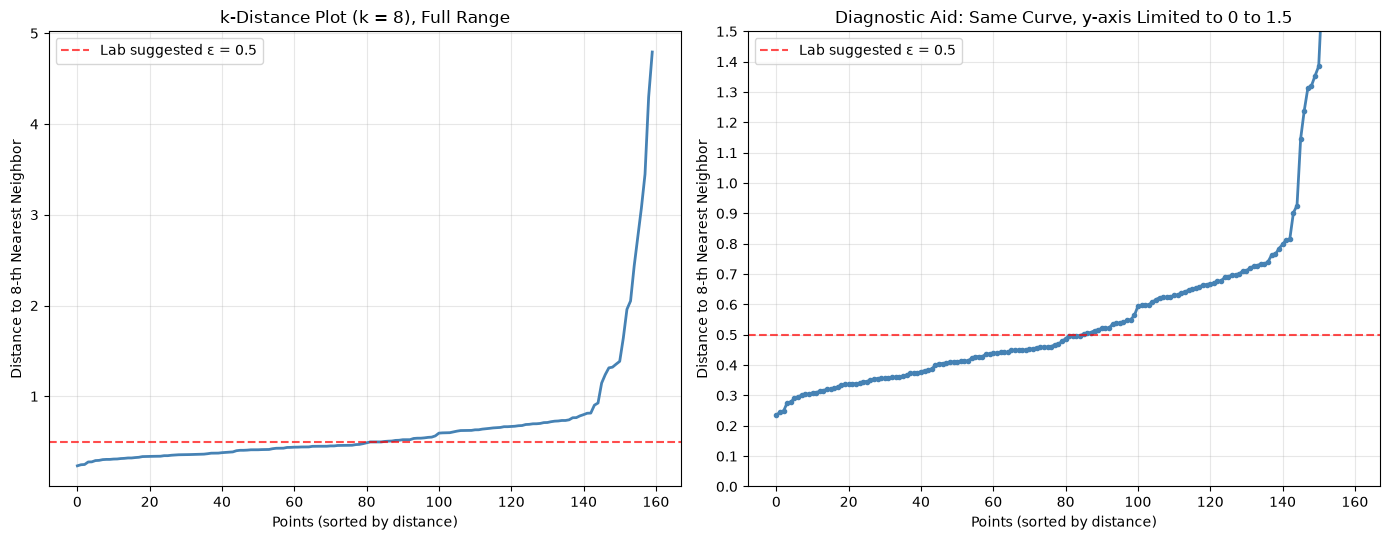

k-DISTANCE PLOT INTERPRETATION
Largest k-distance: 4.7929
Smallest k-distance: 0.2341
Median k-distance: 0.4828

Look for the 'elbow', where the curve bends sharply upward.
The y-value at that bend is the candidate ε.


In [22]:
# Part 3.2: k-distance plot to find eps
k = 2 * len(features)  # = 8, matches MinPts in Part 3.3

neighbors = NearestNeighbors(n_neighbors=k)
neighbors.fit(X_train_scaled)
distances, indices = neighbors.kneighbors(X_train_scaled)
k_distances = np.sort(distances[:, k - 1], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: full curve, as required by the lab
axes[0].plot(k_distances, color='steelblue', linewidth=2)
axes[0].axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Lab suggested ε = 0.5')
axes[0].set_xlabel('Points (sorted by distance)')
axes[0].set_ylabel(f'Distance to {k}-th Nearest Neighbor')
axes[0].set_title(f'k-Distance Plot (k = {k}), Full Range')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Right: diagnostic aid, same curve with the y-axis limited to 0 to 1.5
axes[1].plot(k_distances, color='steelblue', linewidth=2, marker='o', markersize=3)
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Lab suggested ε = 0.5')
axes[1].set_ylim(0, 1.5)
axes[1].set_yticks(np.arange(0, 1.51, 0.1))
axes[1].set_xlabel('Points (sorted by distance)')
axes[1].set_ylabel(f'Distance to {k}-th Nearest Neighbor')
axes[1].set_title('Diagnostic Aid: Same Curve, y-axis Limited to 0 to 1.5')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("=" * 70)
print("k-DISTANCE PLOT INTERPRETATION")
print("=" * 70)
print(f"Largest k-distance: {k_distances.max():.4f}")
print(f"Smallest k-distance: {k_distances.min():.4f}")
print(f"Median k-distance: {np.median(k_distances):.4f}")
print()
print("Look for the 'elbow', where the curve bends sharply upward.")
print("The y-value at that bend is the candidate ε.")

The right-hand plot is a diagnostic aid, not a separate analysis. It shows the same curve with the y-axis limited to 0 to 1.5 so the region where the curve starts to bend is easier to see. The few largest distances (up to about 4.8) are cut off in this view.

The table below gives numeric evidence for reading the curve. For several candidate ε values it shows how many training customers have their 8th-nearest neighbour within that distance. Those customers would be core points at that ε. This is calculated from the k-distances only; DBSCAN has not been fitted yet.

In [23]:
# k-distance percentiles and candidate eps values (no DBSCAN fitted here)
percentile_table = pd.DataFrame({
    "Percentile of Points": [f"{p}%" for p in [25, 50, 75, 85, 90, 95, 100]],
    "k-Distance": [round(np.percentile(k_distances, p), 3) for p in [25, 50, 75, 85, 90, 95, 100]],
})
display(percentile_table)

candidate_eps = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
candidate_table = pd.DataFrame({
    "Candidate ε": candidate_eps,
    "Points With k-Distance ≤ ε (core points)": [int((k_distances <= e).sum()) for e in candidate_eps],
    "Percentage of Training Points": [f"{(k_distances <= e).mean() * 100:.1f}%" for e in candidate_eps],
})
candidate_table

,Percentile of Points,k-Distance
0,25%,0.378
1,50%,0.483
2,75%,0.666
3,85%,0.735
4,90%,0.905
5,95%,1.659
6,100%,4.793


,Candidate ε,Points With k-Distance ≤ ε (core points),Percentage of Training Points
0,0.4,44,27.5%
1,0.5,85,53.1%
2,0.6,104,65.0%
3,0.7,128,80.0%
4,0.8,141,88.1%
5,0.9,143,89.4%
6,1.0,145,90.6%


### How to Read This

Moving down the candidate table, each larger ε turns more customers into core points. Where the curve is flat, a small increase in ε adds many core points. Past the elbow, the curve is steep and a large increase in ε adds only a few.

### What the Output Shows

- The k-distances rise gradually from about 0.23 to about 0.8, which covers 141 of the 160 training points (88.1%). There is no single sharp bend at 0.5.
- At the lab's suggested ε = 0.5, 85 of the 160 training customers (53.1%) are core points. The value 0.5 sits close to the median k-distance (0.483), in the gradual part of the curve.
- The sharpest bend appears after about 0.8 to 0.9. The distances jump from 0.926 to 1.146 and then climb steeply to 4.79 across the last 14 points.
- The elbow on this data is therefore not clearly at 0.5. Reasonable readings of the curve fall somewhere between about 0.5 and 0.9.

The k-distance plot does not show one perfectly sharp elbow. The strongest bend appears higher than 0.5, but the lab specifies ε = 0.5 for this activity. I will use 0.5 for the required DBSCAN model so the assigned workflow can be followed, then compare nearby values later in the stability analysis.

### 3.3 Parameter Selection

DBSCAN is unsupervised, so there is no validation set and no score to tune ε against. The parameters come from the structure of the training data and the lab's rules:

| Parameter | Value | Where It Comes From |
|---|---|---|
| ε (`eps`) | 0.5 | Specified by the lab for this activity (see the k-distance discussion in 3.2) |
| MinPts (`min_samples`) | 8 | Rule of thumb: 2 × number of features = 2 × 4 = 8 |

**MinPts is not the number of clusters.** MinPts = 8 is a rule: a customer needs at least 8 points (including itself) within distance ε to count as a core point. How many clusters DBSCAN finds is not set in advance; it is discovered from the data in 3.4.

*The lab's version of this cell prints "← read from the k-distance elbow". Since 3.2 shows the elbow on this data is not clearly at 0.5, the printed labels below say where each value actually comes from.*

In [24]:
# Part 3.3: Select eps and MinPts
best_eps = 0.5                          # specified by the lab (see 3.2)
best_min_samples = 2 * len(features)    # = 8 for 4 features

print("=" * 70)
print("PARAMETER SELECTION")
print("=" * 70)
print(f"ε (eps): {best_eps}  ← specified by the lab for this activity")
print(f"MinPts: {best_min_samples}  ← rule of thumb: 2 × n_features")
print()
print(f"  - {len(features)} features → MinPts ≥ 2 × {len(features)} = {2 * len(features)}")
print(f"  - Median k-distance on the training data: {np.median(k_distances):.4f}")
print()
print("No validation set is used. DBSCAN has no labels to validate against.")

PARAMETER SELECTION
ε (eps): 0.5  ← specified by the lab for this activity
MinPts: 8  ← rule of thumb: 2 × n_features

  - 4 features → MinPts ≥ 2 × 4 = 8
  - Median k-distance on the training data: 0.4828

No validation set is used. DBSCAN has no labels to validate against.


### 3.4 Apply DBSCAN to the Training Data

DBSCAN is fitted on the standardized training data (`X_train_scaled`) with `eps = 0.5` and `min_samples = 8`.

**Recall: three kinds of points**

- **Core point:** has at least MinPts points within distance ε. It anchors a cluster.
- **Border point:** within ε of a core point but does not have MinPts neighbours itself. It belongs to the cluster but does not extend it.
- **Noise point:** neither a core point nor within ε of one. It is labelled `-1` and is not placed in any cluster.

In [25]:
# Part 3.4: Apply DBSCAN to training data
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_labels = dbscan.fit_predict(X_train_scaled)

# Attach cluster labels back to the training DataFrame
df_train['Cluster'] = dbscan_labels

# Count clusters and noise
unique_labels = set(dbscan_labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print("=" * 70)
print("DBSCAN ON CUSTOMER DATA (TRAINING SET)")
print("=" * 70)
print(f"ε (eps): {best_eps}")
print(f"MinPts (min_samples): {best_min_samples}")
print(f"Training points: {len(dbscan_labels)}")
print()
print(f"Number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise}")
print(f"Percentage of noise: {n_noise / len(dbscan_labels) * 100:.1f}%")
print("\nCluster distribution:")
for label in sorted(unique_labels):
    count = list(dbscan_labels).count(label)
    if label == -1:
        print(f"  Noise (-1): {count:3d} customers ({count / len(dbscan_labels) * 100:4.1f}%)")
    else:
        print(f"  Cluster {label:2d}: {count:3d} customers ({count / len(dbscan_labels) * 100:4.1f}%)")

DBSCAN ON CUSTOMER DATA (TRAINING SET)
ε (eps): 0.5
MinPts (min_samples): 8
Training points: 160

Number of clusters: 5
Number of noise points: 40
Percentage of noise: 25.0%

Cluster distribution:
  Noise (-1):  40 customers (25.0%)
  Cluster  0:  62 customers (38.8%)
  Cluster  1:  19 customers (11.9%)
  Cluster  2:  19 customers (11.9%)
  Cluster  3:  13 customers ( 8.1%)
  Cluster  4:   7 customers ( 4.4%)


In [26]:
# Cluster distribution table, including core and border point counts
core_mask = np.zeros(len(dbscan_labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

dist_rows = []
for label in sorted(unique_labels, key=lambda v: (v == -1, v)):
    in_group = dbscan_labels == label
    dist_rows.append({
        "Group": "Noise (-1)" if label == -1 else f"Cluster {label}",
        "Customers": int(in_group.sum()),
        "Percentage": f"{in_group.mean() * 100:.1f}%",
        "Core Points": int((in_group & core_mask).sum()),
        "Border Points": 0 if label == -1 else int((in_group & ~core_mask).sum()),
    })

cluster_distribution = pd.DataFrame(dist_rows)
total_row = pd.DataFrame([{
    "Group": "Total",
    "Customers": int(cluster_distribution["Customers"].sum()),
    "Percentage": "100.0%",
    "Core Points": int(cluster_distribution["Core Points"].sum()),
    "Border Points": int(cluster_distribution["Border Points"].sum()),
}])
cluster_distribution = pd.concat([cluster_distribution, total_row], ignore_index=True)
cluster_distribution

,Group,Customers,Percentage,Core Points,Border Points
0,Cluster 0,62,38.8%,54,8
1,Cluster 1,19,11.9%,11,8
2,Cluster 2,19,11.9%,12,7
3,Cluster 3,13,8.1%,6,7
4,Cluster 4,7,4.4%,2,5
5,Noise (-1),40,25.0%,0,0
6,Total,160,100.0%,85,35


### How to Read This

| What you see | What it means |
|---|---|
| Number of clusters | How many customer segments DBSCAN found. This was not specified in advance. |
| Noise points | Customers that are not close enough to any dense area to join a cluster |
| Percentage of noise | The lab's guide: 1% to 15% is typical for well-tuned DBSCAN; above 30% suggests ε is too small or MinPts too large |
| Core / Border points | Core points anchor each cluster; border points sit at its edge |

The noise row is not a cluster. It is the "none of the above" group, which is why the cluster count excludes it. The counts in the table add up to the 160 training customers.

### What the Output Shows

- DBSCAN found **5 clusters** and **40 noise points (25.0%)** in the 160 training customers.
- The clusters have 62, 19, 19, 13, and 7 customers. Cluster 0 is the largest at 38.8% of the training data.
- The 25.0% noise is above the lab's 1% to 15% typical range and below its 30% warning level.
- These results match the lab's example output exactly.

### 3.5 Visualize Clusters and Examine Outliers

Each training customer is plotted by Annual Income and Spending Score. Customers in a cluster are coloured by cluster. Noise points are shown as black ×.

DBSCAN used all four features, but this plot only shows two of them, so clusters can overlap here even when they are separated in the full four-feature space.

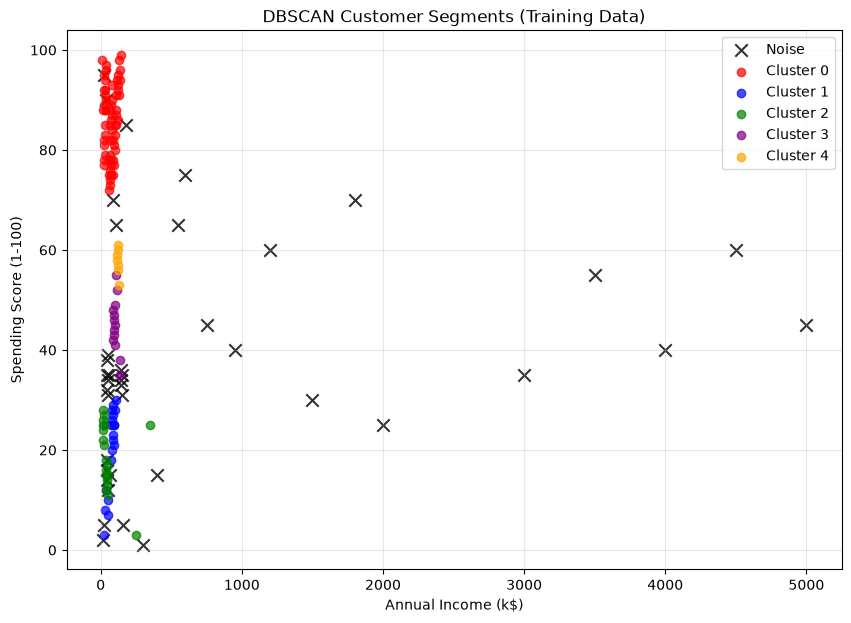

In [27]:
# Part 3.5: Visualize clusters
plt.figure(figsize=(10, 7))

noise_mask = dbscan_labels == -1
plt.scatter(
    X_train['Annual_Income'][noise_mask],
    X_train['Spending_Score'][noise_mask],
    c='black', marker='x', s=80, label='Noise', alpha=0.8
)

colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown']
for i, label in enumerate(sorted(set(dbscan_labels) - {-1})):
    mask = dbscan_labels == label
    plt.scatter(
        X_train['Annual_Income'][mask],
        X_train['Spending_Score'][mask],
        c=colors[i % len(colors)], alpha=0.7, label=f'Cluster {label}'
    )

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('DBSCAN Customer Segments (Training Data)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Additional Views: Making the DBSCAN Structure Easier to See

The full-range plot above is the required complete view and stays unchanged. The two plots below are only for readability. They use the same fitted model, the same cluster labels, and the same colours and noise markers. No customers are removed from the model.

**Why more than one view helps:** DBSCAN grouped customers using all four features at once (income, spending, age, and years as a customer). A scatter plot can only show two features at a time. Two customers can look close together in one plot but still be far apart once the other two features are included, which is why they can end up in different clusters.

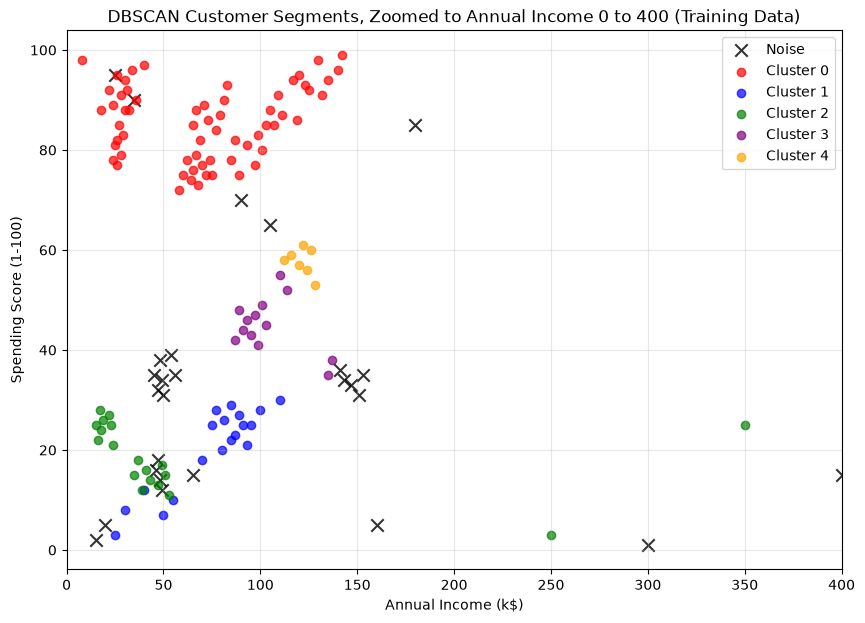

Training customers outside this zoomed view (income above 400): 13, all shown in the full-range plot above (13 of them are noise)


In [28]:
# Shared colours so every view matches the required plot
cluster_ids = sorted(set(dbscan_labels) - {-1})
cluster_colors = {label: colors[i % len(colors)] for i, label in enumerate(cluster_ids)}

def plot_clusters(ax, x_col, y_col):
    noise = dbscan_labels == -1
    ax.scatter(X_train[x_col][noise], X_train[y_col][noise],
               c='black', marker='x', s=80, label='Noise', alpha=0.8)
    for label in cluster_ids:
        mask = dbscan_labels == label
        ax.scatter(X_train[x_col][mask], X_train[y_col][mask],
                   c=cluster_colors[label], alpha=0.7, label=f'Cluster {label}')
    ax.grid(True, alpha=0.3)

# View 1: Income vs Spending Score, zoomed to Annual Income 0 to 400
ZOOM_INCOME = 400
fig, ax = plt.subplots(figsize=(10, 7))
plot_clusters(ax, 'Annual_Income', 'Spending_Score')
ax.set_xlim(0, ZOOM_INCOME)
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title(f'DBSCAN Customer Segments, Zoomed to Annual Income 0 to {ZOOM_INCOME} (Training Data)')
ax.legend()
plt.show()

n_outside = int((X_train['Annual_Income'] > ZOOM_INCOME).sum())
n_outside_noise = int(((X_train['Annual_Income'] > ZOOM_INCOME) & (dbscan_labels == -1)).sum())
print(f"Training customers outside this zoomed view (income above {ZOOM_INCOME}): {n_outside}, "
      f"all shown in the full-range plot above ({n_outside_noise} of them are noise)")

### How to Read This

This is the same plot as the required one, with the x-axis stopped at an income of 400 so the five clusters are no longer squeezed against the left edge. Every clustered customer appears in this view. The customers outside it are only the very high incomes, which are shown in the full-range plot above.

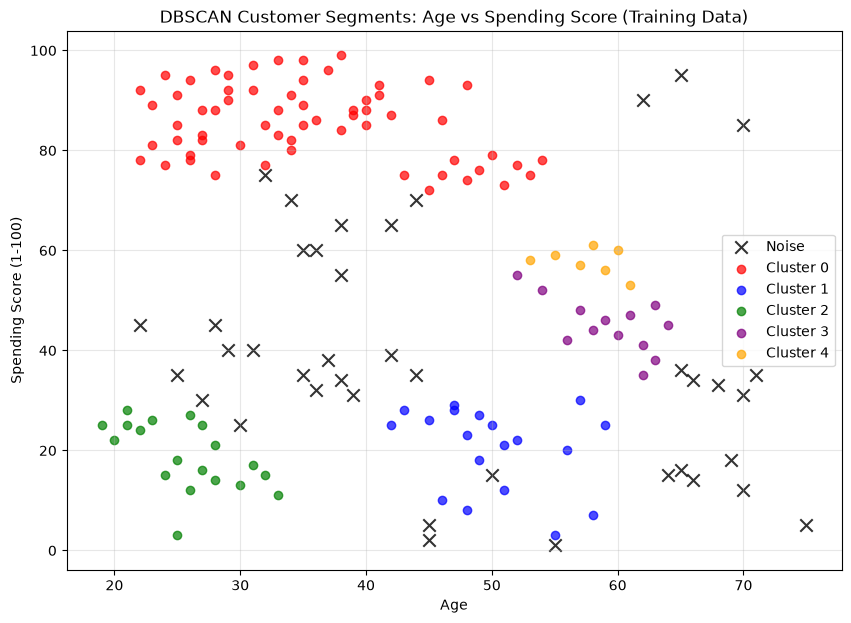

In [29]:
# View 2: Age vs Spending Score, coloured by DBSCAN cluster
fig, ax = plt.subplots(figsize=(10, 7))
plot_clusters(ax, 'Age', 'Spending_Score')
ax.set_xlabel('Age')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title('DBSCAN Customer Segments: Age vs Spending Score (Training Data)')
ax.legend()
plt.show()

### How to Read This

This view swaps income for age. It shows separation that the Income vs Spending plot cannot. Clusters 1 and 2 both have low spending scores (3 to 30) and sit on top of each other in the income plots, but here they separate by age: Cluster 2 covers ages 19 to 33 and Cluster 1 covers ages 42 to 59.

In [30]:
# Range of each feature inside each group (min to max), calculated from df_train
range_rows = []
for label in sorted(unique_labels, key=lambda v: (v == -1, v)):
    group = df_train[df_train['Cluster'] == label]
    row = {"Group": "Noise (-1)" if label == -1 else f"Cluster {label}",
           "Customers": len(group)}
    for col in features:
        row[col] = f"{group[col].min()} to {group[col].max()}"
    range_rows.append(row)

cluster_ranges = pd.DataFrame(range_rows)
cluster_ranges

,Group,Customers,Annual_Income,Spending_Score,Age,Years_Customer
0,Cluster 0,62,8 to 142,72 to 99,22 to 54,1 to 13
1,Cluster 1,19,25 to 110,3 to 30,42 to 59,10 to 17
2,Cluster 2,19,15 to 350,3 to 28,19 to 33,1 to 7
3,Cluster 3,13,87 to 137,35 to 55,52 to 64,13 to 19
4,Cluster 4,7,112 to 128,53 to 61,53 to 61,16 to 20
5,Noise (-1),40,15 to 5000,1 to 95,22 to 75,3 to 25


### How to Read This

The plot shows where each cluster sits on income and spending. The range table gives the smallest and largest value of every feature inside each group, including Age and Years_Customer, which the plot does not show.

### What the Output Shows

- All five clusters sit at the low end of the income axis. Every cluster member has an income of 142 or less except two customers in Cluster 2, with incomes of 250 and 350.
- On spending, Cluster 0 covers high scores (72 to 99), Clusters 1 and 2 cover low scores (3 to 30), and Clusters 3 and 4 cover mid scores (35 to 61).
- Clusters 1 and 2 overlap on the income and spending axes but are separated by age: Cluster 1 is 42 to 59 years old, Cluster 2 is 19 to 33.
- Noise points appear both among the very high incomes and inside the main low-income band.

#### 3.5.1 Examine Outliers

The noise customers are listed below. DBSCAN labels a customer as noise when they are outside every dense area at the chosen ε and MinPts. This does not by itself mean the customer's data is wrong. A noise customer could be a genuine customer with an unusual combination of values, a VIP, a test account, or a data error; the label only says they do not sit in a dense group.

In [31]:
# Part 3.5.1: Examine outliers
outliers_df = df_train[df_train['Cluster'] == -1].copy()

print("=" * 70)
print("OUTLIER ANALYSIS")
print("=" * 70)
print(f"Total outliers: {len(outliers_df)}")
print(f"Percentage: {len(outliers_df) / len(df_train) * 100:.1f}%")
print("\nOutlier customer details (first 10):")
display(outliers_df[['Customer_ID', 'Age', 'Annual_Income', 'Spending_Score', 'Years_Customer']].head(10))

OUTLIER ANALYSIS
Total outliers: 40
Percentage: 25.0%

Outlier customer details (first 10):


,Customer_ID,Age,Annual_Income,Spending_Score,Years_Customer
197,198,42,105,65,12
19,20,44,56,35,9
173,174,62,35,90,17
172,173,29,950,40,5
12,13,37,48,38,6
189,190,25,3000,35,5
136,137,68,147,33,21
162,163,32,600,75,6
139,140,71,153,35,23
191,192,38,3500,55,10


In [32]:
# Noise customers split by whether their Annual_Income is above the IQR fence
income_fence = distribution_summary.loc[0, "IQR Upper Fence"]
noise_high = outliers_df[outliers_df['Annual_Income'] > income_fence]
noise_ordinary = outliers_df[outliers_df['Annual_Income'] <= income_fence]
clustered = df_train[df_train['Cluster'] != -1]

noise_breakdown = pd.DataFrame({
    "Noise Group": [f"Annual_Income above IQR fence (~{income_fence:.0f})",
                    f"Annual_Income at or below IQR fence",
                    "All noise customers"],
    "Customers": [len(noise_high), len(noise_ordinary), len(outliers_df)],
    "Percentage of Noise": [f"{len(noise_high) / len(outliers_df) * 100:.1f}%",
                            f"{len(noise_ordinary) / len(outliers_df) * 100:.1f}%",
                            "100.0%"],
})
display(noise_breakdown)

print(f"High-income training customers labelled noise: {len(noise_high)} of "
      f"{int((df_train['Annual_Income'] > income_fence).sum())}")

# Medians of noise vs clustered customers
median_comparison = pd.DataFrame({
    "Clustered Customers (median)": clustered[features].median(),
    "Noise Customers (median)": outliers_df[features].median(),
}).round(1)
median_comparison

,Noise Group,Customers,Percentage of Noise
0,Annual_Income above IQR fence (~233),15,37.5%
1,Annual_Income at or below IQR fence,25,62.5%
2,All noise customers,40,100.0%


High-income training customers labelled noise: 15 of 17


,Clustered Customers (median),Noise Customers (median)
Annual_Income,76.0,145.0
Spending_Score,73.5,35.0
Age,39.0,43.0
Years_Customer,9.0,10.5


In [33]:
# Representative noise customers: 5 from each noise group
cols = ['Customer_ID', 'Annual_Income', 'Spending_Score', 'Age', 'Years_Customer']
representative_noise = pd.concat([
    noise_high.sort_values('Annual_Income', ascending=False)[cols].head(5)
        .assign(**{"Noise Group": "High income"}),
    noise_ordinary.sort_values('Annual_Income')[cols].head(5)
        .assign(**{"Noise Group": "Ordinary income"}),
]).reset_index(drop=True)
representative_noise

,Customer_ID,Annual_Income,Spending_Score,Age,Years_Customer,Noise Group
0,200,5000,45,28,6,High income
1,197,4500,60,35,9,High income
2,195,4000,40,31,7,High income
3,192,3500,55,38,10,High income
4,190,3000,35,25,5,High income
5,154,15,2,45,12,Ordinary income
6,167,20,5,45,11,Ordinary income
7,155,25,95,65,18,Ordinary income
8,174,35,90,62,17,Ordinary income
9,11,45,35,35,5,Ordinary income


### How to Read This

The breakdown splits the 40 noise customers into those with very high incomes and those whose incomes are in the ordinary range. The median table compares a typical noise customer with a typical clustered customer. The representative table shows five customers from each noise group.

### What the Output Shows

- 15 of the 40 noise customers (37.5%) have an Annual_Income above the IQR fence. These are 15 of the 17 high-income customers in the training set; the other 2 (incomes of 250 and 350) were placed in Cluster 2.
- The other 25 noise customers (62.5%) have ordinary incomes. They are labelled noise because their full combination of income, spending, age, and years as a customer does not have 8 close neighbours within ε = 0.5.
- The median noise customer has a higher income (145 vs 76) and a lower spending score (35 vs 73.5) than the median clustered customer.

### Part 3 Checkpoint

| Variable | What It Is |
|---|---|
| `k_distances` | Sorted distances to the 8th-nearest neighbour (k = 8) |
| `best_eps`, `best_min_samples` | Chosen parameters (0.5, 8) |
| `dbscan` | Fitted DBSCAN model |
| `dbscan_labels` | Cluster labels for the training customers (-1 for noise) |
| `df_train['Cluster']` | Cluster column added to the training DataFrame |
| `cluster_distribution` | Customers, percentages, core and border points per group |
| `cluster_ranges` | Minimum to maximum of each feature in each group |
| `outliers_df` | DataFrame of the noise-point customers |

## Part 4: Model Evaluation

*(MLOps Phase 3, evaluation sub-phase)*

This part scores the DBSCAN model from Part 3 (ε = 0.5, MinPts = 8) in three ways:

1. **Internal metrics:** silhouette score and Davies-Bouldin index.
2. **Stability:** whether the clusters stay similar when ε is nudged up or down.
3. **Business validation:** whether the clusters make sense as customer segments, and how DBSCAN compares with K-Means.

### 4.1 Silhouette Score (Excluding Noise)

The silhouette score (a number from -1 to +1 that compares how close each customer is to their own cluster with how close they are to the nearest other cluster) summarises how well the clusters are separated. A higher score means customers sit well inside their own cluster and away from other clusters.

Noise points are excluded because silhouette needs every point to belong to a cluster, and DBSCAN's `-1` label means "no cluster". The noise percentage is reported next to the score, because a score calculated with 5% noise removed means something different from the same score with 25% removed.

In [34]:
# Part 4.1: Silhouette score (excluding noise)
non_noise_mask = dbscan_labels != -1
n_non_noise = non_noise_mask.sum()

if len(set(dbscan_labels[non_noise_mask])) >= 2:
    dbscan_silhouette = silhouette_score(
        X_train_scaled[non_noise_mask],
        dbscan_labels[non_noise_mask]
    )
    print("=" * 70)
    print("SILHOUETTE SCORE (excluding noise)")
    print("=" * 70)
    print(f"Silhouette Score: {dbscan_silhouette:.4f}")
    print(f"Noise percentage: {n_noise / len(dbscan_labels) * 100:.1f}%")
    print(f"Non-noise points scored: {n_non_noise} / {len(dbscan_labels)}")
else:
    dbscan_silhouette = None
    print("Not enough clusters for silhouette score.")

SILHOUETTE SCORE (excluding noise)
Silhouette Score: 0.4713
Noise percentage: 25.0%
Non-noise points scored: 120 / 160


| Silhouette Score | Lab's Interpretation Guide |
|---|---|
| > 0.7 | Strong structure |
| 0.5 to 0.7 | Reasonable structure |
| 0.3 to 0.5 | Weak structure: check business meaning |
| < 0.3 | Poor structure: reconsider parameters |

### What the Output Shows

- The silhouette score is **0.4713**, calculated on the 120 clustered customers (the 40 noise customers, 25.0%, are excluded).
- On the lab's guide, 0.4713 falls in the 0.3 to 0.5 band.

**Note from the lab:** DBSCAN silhouette should not be compared directly with K-Means silhouette. Silhouette favours round clusters, and DBSCAN can find irregular ones. The lab recommends using silhouette to compare DBSCAN runs with each other, not DBSCAN against K-Means.

### 4.2 Davies-Bouldin Index (Excluding Noise)

The Davies-Bouldin index (a score that compares how spread out each cluster is with how far apart the clusters are) gives a second view of cluster quality. **Lower is better**: a low score means the clusters are compact (tight) and well separated from each other. Noise points are excluded for the same reason as in 4.1.

In [35]:
# Part 4.2: Davies-Bouldin Index (excluding noise)
if len(set(dbscan_labels[non_noise_mask])) >= 2:
    dbscan_db = davies_bouldin_score(
        X_train_scaled[non_noise_mask],
        dbscan_labels[non_noise_mask]
    )
    print("=" * 70)
    print("DAVIES-BOULDIN INDEX (excluding noise)")
    print("=" * 70)
    print(f"Davies-Bouldin Index: {dbscan_db:.4f}")
    print(f"Non-noise points scored: {n_non_noise} / {len(dbscan_labels)}")

DAVIES-BOULDIN INDEX (excluding noise)
Davies-Bouldin Index: 0.7833
Non-noise points scored: 120 / 160


| Davies-Bouldin Index | Lab's Interpretation Guide |
|---|---|
| < 0.5 | Excellent separation |
| 0.5 to 1.0 | Good separation |
| 1.0 to 2.0 | Acceptable |
| > 2.0 | Poor: clusters overlap |

### What the Output Shows

- The Davies-Bouldin index is **0.7833**, calculated on the same 120 clustered customers.
- On the lab's guide, 0.7833 falls in the 0.5 to 1.0 band.

### 4.3 Cluster Profiles

A cluster profile turns cluster numbers into something a marketing team can read. Each value below is the **mean** (average) of that feature across the customers in the cluster. Noise customers are not included.

In [36]:
# Part 4.3: Profile each cluster (means)
cluster_profile = (
    df_train[df_train['Cluster'] != -1]
    .groupby('Cluster')[['Age', 'Annual_Income', 'Spending_Score', 'Years_Customer']]
    .mean()
    .round(2)
)

print("=" * 70)
print("CLUSTER PROFILES (means)")
print("=" * 70)
display(cluster_profile)

CLUSTER PROFILES (means)


,Age,Annual_Income,Spending_Score,Years_Customer
Cluster,,,,
0,35.29,71.18,85.63,6.97
1,50.16,74.63,20.37,13.84
2,25.68,60.47,18.79,3.63
3,59.31,103.92,45.00,15.77
4,57.57,121.14,57.71,18.14


#### Additional Analysis: Median Profiles

The lab notes that a mean can be pulled up by a single extreme value, and that the median (the middle value) is more robust in that case. Cluster 2 contains two customers with incomes of 250 and 350, while its other members earn far less, so the medians are shown here alongside the required means.

In [37]:
# Additional analysis: medians next to the required means
cluster_median = (
    df_train[df_train['Cluster'] != -1]
    .groupby('Cluster')[['Age', 'Annual_Income', 'Spending_Score', 'Years_Customer']]
    .median()
)

profile_comparison = pd.DataFrame({
    "Customers": df_train[df_train['Cluster'] != -1].groupby('Cluster').size(),
    "Mean Age": cluster_profile['Age'],
    "Median Age": cluster_median['Age'],
    "Mean Income": cluster_profile['Annual_Income'],
    "Median Income": cluster_median['Annual_Income'],
    "Mean Spending": cluster_profile['Spending_Score'],
    "Median Spending": cluster_median['Spending_Score'],
    "Mean Years": cluster_profile['Years_Customer'],
    "Median Years": cluster_median['Years_Customer'],
})
profile_comparison

,Customers,Mean Age,Median Age,Mean Income,Median Income,Mean Spending,Median Spending,Mean Years,Median Years
Cluster,,,,,,,,,
0,62,35.29,34.0,71.18,70.5,85.63,86.0,6.97,7.0
1,19,50.16,49.0,74.63,81.0,20.37,23.0,13.84,14.0
2,19,25.68,26.0,60.47,37.0,18.79,18.0,3.63,3.0
3,13,59.31,60.0,103.92,99.0,45.00,45.0,15.77,16.0
4,7,57.57,58.0,121.14,122.0,57.71,58.0,18.14,18.0


### What the Output Shows

- **Cluster 0** (62 customers): mean age 35.3, mean spending 85.6, the highest spending of any cluster.
- **Cluster 1** (19): mean age 50.2, mean spending 20.4, mean years as a customer 13.8.
- **Cluster 2** (19): mean age 25.7, mean spending 18.8, mean years as a customer 3.6. Its mean income (60.5) is well above its median income (37.0) because of the two customers at 250 and 350.
- **Cluster 3** (13): mean age 59.3, mean income 103.9, mean spending 45.0.
- **Cluster 4** (7): mean age 57.6, mean income 121.1 (the highest mean income), mean spending 57.7, mean years as a customer 18.1 (the longest).
- For every cluster except Cluster 2, the mean and median are close.

#### 4.3.1 Assign Business Names from Profiles

The lab's `infer_name()` function applies fixed business rules to each cluster's **mean** profile. The rules are checked in order and the **first rule that matches wins**:

| Order | Rule | Name |
|---|---|---|
| 1 | Age < 40 and Spending ≥ 60 | Young Spenders |
| 2 | Age < 40 and Spending < 40 | New Low-Spenders |
| 3 | Age ≥ 40 and Spending < 40 | Frugal Mature |
| 4 | Age ≥ 40 and Income > 100 and Spending ≥ 50 | Premium Loyalists |
| 5 | Age ≥ 40 and Years > 15 | Loyal Veterans |
| none | No rule matches | Segment N (placeholder) |

**These names are rule-based labels written by the lab, not facts discovered by DBSCAN.** DBSCAN only produces cluster numbers. The names come from thresholds chosen by a person, so a different business could use different rules and get different names for the same clusters.

In [38]:
# Part 4.3.1: Assign business names from profiles
def infer_name(profile):
    '''Assign a plausible business name from a cluster's profile.'''
    age = profile['Age']
    income = profile['Annual_Income']
    spending = profile['Spending_Score']
    tenure = profile['Years_Customer']

    if age < 40 and spending >= 60:
        return "Young Spenders"
    if age < 40 and spending < 40:
        return "New Low-Spenders"
    if age >= 40 and spending < 40:
        return "Frugal Mature"
    if age >= 40 and income > 100 and spending >= 50:
        return "Premium Loyalists"
    if age >= 40 and tenure > 15:
        return "Loyal Veterans"
    return f"Segment {profile.name}"

cluster_names = {
    cid: infer_name(cluster_profile.loc[cid])
    for cid in cluster_profile.index
}
cluster_names[-1] = "Anomalies"

print("=" * 70)
print("CLUSTER NAMES")
print("=" * 70)
for cid, name in cluster_names.items():
    count = len(df_train[df_train['Cluster'] == cid])
    print(f"  Cluster {cid} ({name}): {count} customers")

print()
print("Business actions per segment:")
business_actions = {
    "Young Spenders": "Social media campaigns, trendy products",
    "Frugal Mature": "Value-oriented offers, loyalty reminders",
    "New Low-Spenders": "Onboarding campaigns, welcome offers",
    "Loyal Veterans": "Retention offers, referral programs",
    "Premium Loyalists": "VIP treatment, exclusive offers",
    "Anomalies": "Investigate individually, possible fraud or data errors",
}
for cid, name in cluster_names.items():
    action = business_actions.get(name, "Investigate segment")
    print(f"  {name}: {action}")

CLUSTER NAMES
  Cluster 0 (Young Spenders): 62 customers
  Cluster 1 (Frugal Mature): 19 customers
  Cluster 2 (New Low-Spenders): 19 customers
  Cluster 3 (Loyal Veterans): 13 customers
  Cluster 4 (Premium Loyalists): 7 customers
  Cluster -1 (Anomalies): 40 customers

Business actions per segment:
  Young Spenders: Social media campaigns, trendy products
  Frugal Mature: Value-oriented offers, loyalty reminders
  New Low-Spenders: Onboarding campaigns, welcome offers
  Loyal Veterans: Retention offers, referral programs
  Premium Loyalists: VIP treatment, exclusive offers
  Anomalies: Investigate individually, possible fraud or data errors


In [39]:
# Profiles, generated names, and suggested actions in one table
naming_summary = cluster_profile.copy()
naming_summary.insert(0, "Customers", df_train[df_train['Cluster'] != -1].groupby('Cluster').size())
naming_summary["Rule-Generated Name"] = [cluster_names[c] for c in naming_summary.index]
naming_summary["Lab's Suggested Action"] = [business_actions.get(cluster_names[c], "Investigate segment")
                                            for c in naming_summary.index]
naming_summary

,Customers,Age,Annual_Income,Spending_Score,Years_Customer,Rule-Generated Name,Lab's Suggested Action
Cluster,,,,,,,
0,62,35.29,71.18,85.63,6.97,Young Spenders,"Social media campaigns, trendy products"
1,19,50.16,74.63,20.37,13.84,Frugal Mature,"Value-oriented offers, loyalty reminders"
2,19,25.68,60.47,18.79,3.63,New Low-Spenders,"Onboarding campaigns, welcome offers"
3,13,59.31,103.92,45.00,15.77,Loyal Veterans,"Retention offers, referral programs"
4,7,57.57,121.14,57.71,18.14,Premium Loyalists,"VIP treatment, exclusive offers"


### What the Output Shows

- Every cluster received a name, so no "Segment N" placeholder appears and no two clusters share a name.
- Cluster 3 does not meet the Premium Loyalists rule because its mean spending (45.0) is below 50, so it falls through to Loyal Veterans (mean years 15.77 > 15).
- The 40 noise customers are labelled "Anomalies". The lab's suggested action for them mentions possible fraud or data errors; as noted in 3.5.1, noise only means a customer is outside every dense group.

#### 4.3.2 Aligning Profiles with the Business Case

The profiles are calculated; the names are a business decision. The lab's alignment test asks three questions for each cluster:

1. Does the profile describe a real customer type the business recognizes?
2. Does the segment map to an existing or proposed business action?
3. Would the marketing team agree with this name if it had to be defended in a meeting?

If a profile does not align, the lab gives three options: re-examine the parameters, return to the business context (the cluster may be a real customer type the business has not recognized yet), or label it honestly (for example "Unclassified, Investigate") instead of forcing a name.

The generated names mostly fit the cluster profiles because Young Spenders, Frugal Mature, New Low-Spenders, Loyal Veterans and Premium Loyalists all match the main age, spending, income and customer history patterns in their groups. I would say to be more careful with the Anomalies group though. I think investigating them separately makes sense, but being labelled as noise doesn't for sure mean fraud or that it's bad data. Some may just be real customers that do not fit in the main dense groups.

### 4.4 Cluster Stability Check

Stability asks: if ε is nudged slightly, do the clusters stay the same? A cluster that disappears when ε moves by 0.05 may only exist because of that exact parameter value.

The comparison uses the ARI (Adjusted Rand Index, a score that measures how much two clusterings agree; 1.0 means identical groupings, 0.0 means no more agreement than random). Each nearby ε is compared with the ε = 0.5 baseline. MinPts stays at 8 throughout.

In [40]:
# Part 4.4: Cluster stability check
print("=" * 70)
print("CLUSTER STABILITY CHECK")
print("=" * 70)
print(f"Baseline: ε = {best_eps}, MinPts = {best_min_samples}")
print()

eps_nearby = [best_eps - 0.1, best_eps - 0.05, best_eps, best_eps + 0.05, best_eps + 0.1]
stability_rows = []

for eps in eps_nearby:
    labels_test = DBSCAN(eps=eps, min_samples=best_min_samples).fit_predict(X_train_scaled)
    n_clusters_test = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_noise_test = list(labels_test).count(-1)
    noise_pct_test = n_noise_test / len(labels_test) * 100

    if np.isclose(eps, best_eps):
        ari = 1.0
        ari_text = "baseline"
    else:
        ari = adjusted_rand_score(dbscan_labels, labels_test)
        ari_text = f"ARI = {ari:.3f}"

    print(f"  eps = {eps:.2f}: {n_clusters_test} clusters, "
          f"{noise_pct_test:.1f}% noise, {ari_text}")

    stability_rows.append({
        "ε": round(eps, 2),
        "Clusters": n_clusters_test,
        "Noise Customers": n_noise_test,
        "Noise %": f"{noise_pct_test:.1f}%",
        "ARI vs ε = 0.5": "baseline" if ari_text == "baseline" else round(ari, 3),
    })

CLUSTER STABILITY CHECK
Baseline: ε = 0.5, MinPts = 8

  eps = 0.40: 3 clusters, 54.4% noise, ARI = 0.377
  eps = 0.45: 4 clusters, 36.2% noise, ARI = 0.793
  eps = 0.50: 5 clusters, 25.0% noise, baseline
  eps = 0.55: 3 clusters, 21.2% noise, ARI = 0.806
  eps = 0.60: 4 clusters, 15.6% noise, ARI = 0.727


In [41]:
# Stability results as a table, with the lab's ARI guide applied
def ari_guide(value):
    if value == "baseline":
        return "Baseline"
    if value > 0.8:
        return "Stable"
    if value >= 0.5:
        return "Moderately stable"
    return "Unstable"

stability_table = pd.DataFrame(stability_rows)
stability_table["Lab's ARI Guide"] = stability_table["ARI vs ε = 0.5"].apply(ari_guide)
stability_table

,ε,Clusters,Noise Customers,Noise %,ARI vs ε = 0.5,Lab's ARI Guide
0,0.40,3,87,54.4%,0.377,Unstable
1,0.45,4,58,36.2%,0.793,Moderately stable
2,0.50,5,40,25.0%,baseline,Baseline
3,0.55,3,34,21.2%,0.806,Stable
4,0.60,4,25,15.6%,0.727,Moderately stable


| ARI vs Baseline | Lab's Interpretation Guide |
|---|---|
| > 0.8 | Stable: the result is robust |
| 0.5 to 0.8 | Moderately stable: check business meaning |
| < 0.5 | Unstable: the result depends on the exact ε |

### How to Read This

Each row reruns DBSCAN at a different ε on the same training data. "Clusters" and "Noise" show what that run found. The ARI shows how closely its groupings match the ε = 0.5 model. A high ARI can still appear when the number of clusters changes, because ARI looks at whether pairs of customers end up grouped together. If two small clusters merge, most customer pairs are still grouped the same way.

### What the Output Shows

- **ε = 0.40:** 3 clusters, 54.4% noise, ARI 0.377 (below 0.5 on the guide). More than half of the training customers become noise.
- **ε = 0.45:** 4 clusters, 36.2% noise, ARI 0.793 (0.5 to 0.8 on the guide).
- **ε = 0.55:** 3 clusters, 21.2% noise, ARI 0.806 (above 0.8 on the guide).
- **ε = 0.60:** 4 clusters, 15.6% noise, ARI 0.727 (0.5 to 0.8 on the guide).
- The number of clusters changes at every step away from 0.5 (5 at the baseline; 3 or 4 at the nearby values).

These results match the lab's example output.

### 4.5 K-Means Baseline on the Customer Data

K-Means is run on the same scaled training data, with the same number of clusters DBSCAN found (5), so the two methods can be compared.

**The key difference:** K-Means assigns **every** customer to the nearest cluster centre. It has no "none of the above" option. DBSCAN can leave customers unassigned as noise. So the K-Means silhouette below is calculated on all 160 customers, while the DBSCAN silhouette is calculated on the 120 clustered customers only.

In [42]:
# Part 4.5: Compare DBSCAN to K-Means on the customer data
kmeans_customer = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
kmeans_customer_labels = kmeans_customer.fit_predict(X_train_scaled)
kmeans_sil = silhouette_score(X_train_scaled, kmeans_customer_labels)

print("=" * 70)
print("DBSCAN vs K-MEANS: CUSTOMER DATA")
print("=" * 70)
print(f"DBSCAN: {n_clusters} clusters, {n_noise} noise points "
      f"({n_noise / len(dbscan_labels) * 100:.1f}%)")
print(f"  Silhouette (excl. noise): {dbscan_silhouette:.4f}")
print(f"  DB Index (excl. noise): {dbscan_db:.4f}")
print()
print(f"K-Means: {n_clusters} clusters, 0 noise points (assigns all points)")
print(f"  Silhouette: {kmeans_sil:.4f}")
print()
print("Note: K-Means forces every point into a cluster, including outliers.")
print("DBSCAN's advantage is that it isolates anomalous customers.")

DBSCAN vs K-MEANS: CUSTOMER DATA
DBSCAN: 5 clusters, 40 noise points (25.0%)
  Silhouette (excl. noise): 0.4713
  DB Index (excl. noise): 0.7833

K-Means: 5 clusters, 0 noise points (assigns all points)
  Silhouette: 0.4487

Note: K-Means forces every point into a cluster, including outliers.
DBSCAN's advantage is that it isolates anomalous customers.


The table below puts both models side by side. The K-Means Davies-Bouldin index is not part of the lab's code; it is added here as additional analysis so both metrics appear for both methods.

In [43]:
# Side-by-side comparison (K-Means Davies-Bouldin is additional analysis)
kmeans_db = davies_bouldin_score(X_train_scaled, kmeans_customer_labels)

comparison_table = pd.DataFrame({
    "Algorithm": ["DBSCAN", "K-Means"],
    "Clusters": [n_clusters, n_clusters],
    "Noise Customers": [n_noise, 0],
    "Customers Scored": [int(n_non_noise), len(kmeans_customer_labels)],
    "Silhouette": [round(dbscan_silhouette, 4), round(kmeans_sil, 4)],
    "Davies-Bouldin": [round(dbscan_db, 4), round(kmeans_db, 4)],
    "Cluster Sizes": [
        ", ".join(str(int((dbscan_labels == c).sum())) for c in sorted(set(dbscan_labels) - {-1})),
        ", ".join(str(int((kmeans_customer_labels == c).sum())) for c in range(n_clusters)),
    ],
})
comparison_table

,Algorithm,Clusters,Noise Customers,Customers Scored,Silhouette,Davies-Bouldin,Cluster Sizes
0,DBSCAN,5,40,120,0.4713,0.7833,"62, 19, 19, 13, 7"
1,K-Means,5,0,160,0.4487,0.6879,"37, 54, 6, 30, 33"


The cross-tabulation below shows where each DBSCAN group ended up under K-Means. Rows are DBSCAN groups (with `-1` for noise); columns are K-Means clusters; each cell counts customers.

In [44]:
# Where DBSCAN's clusters and noise customers land under K-Means
crosstab = pd.crosstab(
    pd.Series(dbscan_labels, name="DBSCAN Group").map(lambda c: "Noise (-1)" if c == -1 else f"DBSCAN {c}"),
    pd.Series(kmeans_customer_labels, name="K-Means Cluster").map(lambda c: f"K-Means {c}"),
)
crosstab

K-Means Cluster,K-Means 0,K-Means 1,K-Means 2,K-Means 3,K-Means 4
DBSCAN Group,,,,,
DBSCAN 0,36,0,0,0,26
DBSCAN 1,0,18,0,1,0
DBSCAN 2,0,0,0,19,0
DBSCAN 3,0,13,0,0,0
DBSCAN 4,0,7,0,0,0
Noise (-1),1,16,6,10,7


### What the Output Shows

- K-Means placed all 160 customers into 5 clusters of 37, 54, 6, 30, and 33 customers. DBSCAN placed 120 customers into clusters of 62, 19, 19, 13, and 7, and left 40 as noise.
- K-Means silhouette: **0.4487** (all 160 customers). DBSCAN silhouette: **0.4713** (120 clustered customers).
- K-Means Davies-Bouldin: **0.6879**. DBSCAN Davies-Bouldin: **0.7833**.
- In the cross-tabulation, the 40 DBSCAN noise customers are spread across all five K-Means clusters. K-Means Cluster 2 (6 customers) is made up entirely of DBSCAN noise customers.
- DBSCAN Cluster 0 (62 customers) is split between two K-Means clusters (36 and 26).
- DBSCAN Clusters 1, 3, and 4 are mostly combined into one K-Means cluster (K-Means 1), together with 16 DBSCAN noise customers.

The DBSCAN silhouette, Davies-Bouldin, and K-Means silhouette match the lab's example output. The lab's code does not print a K-Means Davies-Bouldin index.

**Discussion question from the lab:** Which algorithm gives a more useful answer for the marketing team, and why?

I believe DBSCAN gives the marketing team the better/more useful answer for the dataset. It found five customer groups but also showed 40 customers that did not fit closely enough into those groups, instead of forcing every customer into a segment. K-Means still made reasonable clusters, but it still assigned all of the noise customers somewhere even when they may not fit well. Since the business question is also asking about unusual customers that do not fit a normal segment, I think DBSCAN matches it a lot better.

### Part 4 Checkpoint

| Variable | What It Is |
|---|---|
| `dbscan_silhouette` | Silhouette score (excluding noise) |
| `dbscan_db` | Davies-Bouldin index (excluding noise) |
| `cluster_profile` | Mean values per cluster |
| `profile_comparison` | Means and medians per cluster (additional analysis) |
| `cluster_names` | Rule-based business labels for each cluster |
| `stability_table` | Clusters, noise, and ARI at nearby ε values |
| `kmeans_customer_labels` | K-Means labels (for comparison) |
| `comparison_table` | DBSCAN and K-Means metrics side by side |

## Part 5: Deployment and Serving

*(MLOps Phase 4)*

This part packages the trained model so it can be used on new customers. Every piece needed for inference (using a trained model to make predictions on new data) is saved into one file, a new customer from the untouched test set is passed through the saved pipeline, and the assignment logic is wrapped in a reusable function.

### 5.1 Save Preprocessing and Model Artifacts (Model Registry)

All the pieces needed to score a new customer are saved together in one file, `customer_dbscan_artifacts.pkl`, in the same folder as this notebook (`Codes`). A single file acts as a simple model registry (the one place a deployed system loads its model from), so a separate inference script cannot end up with a missing piece.

The file is saved with `joblib` (a library for saving and loading Python objects to disk). The Activity 4 files in this folder (`iris_kmeans_model.pkl`, `iris_scaler.pkl`) are not touched.

In [45]:
# Part 5.1: Save ALL artifacts needed for inference
ARTIFACT_FILE = "customer_dbscan_artifacts.pkl"

artifacts = {
    'scaler': scaler,
    'model': dbscan,
    'labels': dbscan_labels,
    'core_points': dbscan.components_,
    'core_labels': dbscan_labels[dbscan.core_sample_indices_],
    'cluster_names': cluster_names,
    'features': features,
    'eps': dbscan.eps,
    'min_samples': dbscan.min_samples,
}

joblib.dump(artifacts, ARTIFACT_FILE)

print("=" * 70)
print("ARTIFACTS SAVED")
print("=" * 70)
print(f"Single file: {ARTIFACT_FILE}")
print(f"Saved to: {os.path.abspath(ARTIFACT_FILE)}")
print()
print("Contents:")
for key in artifacts:
    print(f"  - {key}")

ARTIFACTS SAVED
Single file: customer_dbscan_artifacts.pkl
Saved to: d:\Documents_D\RDP_Fall_2026\AIDA2152_MLA2\Codes\customer_dbscan_artifacts.pkl

Contents:
  - scaler
  - model
  - labels
  - core_points
  - core_labels
  - cluster_names
  - features
  - eps
  - min_samples


In [46]:
# What is stored in the artifact file, and what each item is for
def describe_value(value):
    if hasattr(value, "shape"):
        return f"array, shape {value.shape}"
    if isinstance(value, dict):
        return f"dict, {len(value)} entries"
    if isinstance(value, list):
        return f"list, {len(value)} items"
    if isinstance(value, (int, float, np.integer, np.floating)):
        return str(value)
    return type(value).__name__

artifact_purpose = {
    'scaler': "Fitted StandardScaler; must be the same one used in training",
    'model': "The trained DBSCAN object",
    'labels': "Cluster labels for the 160 training customers",
    'core_points': "The scaled positions of DBSCAN's true core points",
    'core_labels': "The cluster label of each core point",
    'cluster_names': "Business label for each cluster number (from 4.3.1)",
    'features': "Feature names in the order the scaler expects",
    'eps': "ε used to fit the model",
    'min_samples': "MinPts used to fit the model",
}

artifact_table = pd.DataFrame({
    "Key": list(artifacts.keys()),
    "Stored Value": [describe_value(v) for v in artifacts.values()],
    "Purpose": [artifact_purpose[k] for k in artifacts],
})
artifact_table

,Key,Stored Value,Purpose
0,scaler,StandardScaler,Fitted StandardScaler; must be the same one us...
1,model,DBSCAN,The trained DBSCAN object
2,labels,"array, shape (160,)",Cluster labels for the 160 training customers
3,core_points,"array, shape (85, 4)",The scaled positions of DBSCAN's true core points
4,core_labels,"array, shape (85,)",The cluster label of each core point
5,cluster_names,"dict, 6 entries",Business label for each cluster number (from 4...
6,features,"list, 4 items",Feature names in the order the scaler expects
7,eps,0.5,ε used to fit the model
8,min_samples,8,MinPts used to fit the model


### How to Read This

`core_points` holds only DBSCAN's **true core points** (`dbscan.components_`), not every clustered customer. Border points belong to a cluster but do not anchor it, so new customers are matched against core points only (see 5.4). The number of core points equals the 85 core points counted in 3.4.

### 5.2 Simulate a New Customer

The first customer in the test set is used as a "new" customer arriving at the deployed model. The 40 test customers were held out in 2.5 and were not used to fit the scaler, fit DBSCAN, choose ε, or calculate any Part 4 score. This customer has never been seen by the model, so the result reflects how the pipeline handles new data rather than data it has already memorised.

One customer is enough to show the full pipeline working end to end. The function in 5.5 handles any number of customers.

In [47]:
# Part 5.2: Take a truly unseen customer from the test set
new_customer_df = X_test.iloc[[0]]
new_customer = new_customer_df.values

print("Simulated new customer (feature values used by the model):")
display(new_customer_df)

print("\nCorresponding raw customer row (with Customer_ID):")
display(df_test.iloc[[0]])

print("\nFeature array shape:", new_customer.shape)

Simulated new customer (feature values used by the model):


,Annual_Income,Spending_Score,Age,Years_Customer
95,95,84,31,7



Corresponding raw customer row (with Customer_ID):


,Customer_ID,Age,Annual_Income,Spending_Score,Years_Customer
95,96,31,95,84,7



Feature array shape: (1, 4)


### 5.3 Apply the Saved Preprocessing

The new customer is scaled with the scaler fitted on the training data, using `transform()` and **not** `fit_transform()`. A new customer has to be measured on exactly the same scale DBSCAN was trained on. Refitting the scaler would change the means and standard deviations, so the new customer's scaled values would no longer line up with the core points.

In [48]:
# Part 5.3: Transform the new customer using the fitted scaler (transform, NOT fit)
new_customer_scaled = scaler.transform(new_customer)

print("Standardized new customer:")
print(new_customer_scaled)

Standardized new customer:
[[-0.22113771  1.00085358 -0.77135583 -0.51399958]]


In [49]:
# Raw and scaled values side by side, using the means and stds learned in 2.6
scaling_check = pd.DataFrame({
    "Feature": features,
    "Raw Value": new_customer[0],
    "Training Mean": scaler.mean_.round(2),
    "Training Std": scaler.scale_.round(2),
    "Scaled Value": new_customer_scaled[0].round(4),
})
scaling_check

,Feature,Raw Value,Training Mean,Training Std,Scaled Value
0,Annual_Income,95,257.49,734.78,-0.2211
1,Spending_Score,84,53.80,30.17,1.0009
2,Age,31,41.91,14.15,-0.7714
3,Years_Customer,7,9.96,5.75,-0.5140


### How to Read This

Each scaled value is (raw value − training mean) ÷ training standard deviation. A scaled value near 0 means the customer is close to the average training customer on that feature; +1 or −1 means one standard deviation above or below.

### 5.4 Assign the New Customer Using True Core Points

The saved artifact file is loaded back in, as a separate deployment script would do, and the new customer is assigned using only what was saved:

1. Find the **nearest core point** to the new customer (in scaled space).
2. If that distance is **within ε**, the customer joins that core point's cluster.
3. If it is **beyond ε**, the customer is labelled **noise**: they do not fit any existing segment.

This mirrors how DBSCAN builds clusters: a point belongs to a cluster only if it is within ε of a core point.

In [50]:
# Part 5.4: Assign the new customer to the nearest CORE point
# Load the saved artifacts (in a real deployment, this would be a separate script)
artifacts = joblib.load(ARTIFACT_FILE)
core_points = artifacts['core_points']
core_labels = artifacts['core_labels']
cluster_names = artifacts['cluster_names']
model_eps = artifacts['eps']

# Find the nearest core point to the new customer
nbrs = NearestNeighbors(n_neighbors=1).fit(core_points)
distances, indices = nbrs.kneighbors(new_customer_scaled)
nearest_core_label = core_labels[indices[0][0]]
nearest_distance = distances[0][0]

print("=" * 70)
print("NEW CUSTOMER ASSIGNMENT")
print("=" * 70)
print(f"Nearest core point distance: {nearest_distance:.4f}")
print(f"DBSCAN ε: {model_eps}")
if nearest_distance <= model_eps:
    print(f"Assigned cluster: {nearest_core_label}")
    print(f"Business label: {cluster_names.get(nearest_core_label, 'Unknown')}")
    print("Noise: No")
else:
    print("Assigned cluster: NOISE (nearest core point is beyond ε)")
    print("This customer does not fit any existing segment.")
    print("Noise: Yes")
print("=" * 70)

NEW CUSTOMER ASSIGNMENT
Nearest core point distance: 0.2124
DBSCAN ε: 0.5
Assigned cluster: 0
Business label: Young Spenders
Noise: No


**Why `components_` and `core_sample_indices_` line up:** row *i* of `dbscan.components_` is the core point at position *i* in `dbscan.core_sample_indices_`. That is why `core_labels` was built in 5.1 by indexing `dbscan_labels` with `core_sample_indices_`.

#### 5.4.1 The Noise Case: When the Model Rejects a Customer

5.4 showed a successful assignment. This step tests the other path: whether the deployed logic can **reject** a customer who fits no segment.

The customer below is **artificial**. It is not a real record from the dataset. It is placed at 10 on every scaled feature (10 standard deviations above the training average on income, spending, age, and years as a customer), far from every core point. This is an edge case (an extreme input used to test that the logic handles it correctly), used only to check that the rejection path works.

In [51]:
# Part 5.4.1: Simulate an artificial customer far from every core point
# In standardized space, (10, 10, 10, 10) is 10 standard deviations above the mean on every feature
far_customer_scaled = np.array([[10.0, 10.0, 10.0, 10.0]])

# Reuse the same logic as 5.4
nbrs = NearestNeighbors(n_neighbors=1).fit(core_points)
distances, indices = nbrs.kneighbors(far_customer_scaled)
far_distance = distances[0][0]
far_label = core_labels[indices[0][0]]

print("=" * 70)
print("ANOMALOUS CUSTOMER ASSIGNMENT (artificial test case)")
print("=" * 70)
print(f"Nearest core point distance: {far_distance:.4f}")
print(f"DBSCAN ε: {model_eps}")
if far_distance <= model_eps:
    print(f"Assigned cluster: {far_label}")
    print(f"Business label: {cluster_names.get(far_label, 'Unknown')}")
else:
    print("Assigned cluster: NOISE (nearest core point is beyond ε)")
    print("This customer does not fit any existing segment.")
print("=" * 70)

ANOMALOUS CUSTOMER ASSIGNMENT (artificial test case)
Nearest core point distance: 18.8537
DBSCAN ε: 0.5
Assigned cluster: NOISE (nearest core point is beyond ε)
This customer does not fit any existing segment.


### What the Output Shows

The artificial customer's nearest core point is about 18.85 scaled units away, far beyond ε = 0.5, so the deployed logic returns **NOISE** instead of forcing the customer into a cluster. K-Means would always assign a customer like this to its nearest cluster centre.

### 5.5 Wrap Inference in a Reusable Function

A notebook cell that prints a result cannot be called by another system. A function that takes customers and returns structured predictions can, for example from an API, a batch job, or a test. `predict_customer_cluster()` packages the steps from 5.3 and 5.4 so it can score one customer or many.

Two demonstrations follow:

1. **One customer:** the same test customer from 5.2.
2. **A batch of five:** the first five test customers, scored in one call.

In [52]:
# Part 5.5: Reusable inference function
def predict_customer_cluster(new_customer, artifacts):
    '''
    Assign one or more new customers to a DBSCAN cluster.

    Parameters
    ----------
    new_customer : np.ndarray, shape (n, 4)
        Raw (unscaled) customer features in the order of artifacts['features'].
        Pass df.values, not the DataFrame itself.
    artifacts : dict
        Loaded from customer_dbscan_artifacts.pkl

    Returns
    -------
    list of dict, one per customer:
        [{'cluster': int, 'label': str, 'distance': float, 'is_noise': bool}, ...]
    '''
    scaler = artifacts['scaler']
    core_points = artifacts['core_points']
    core_labels = artifacts['core_labels']
    cluster_names = artifacts['cluster_names']
    model_eps = artifacts['eps']

    X_scaled = scaler.transform(new_customer)
    nbrs = NearestNeighbors(n_neighbors=1).fit(core_points)
    distances, indices = nbrs.kneighbors(X_scaled)

    results = []
    for i in range(len(X_scaled)):
        dist = distances[i][0]
        if dist <= model_eps:
            cluster_id = int(core_labels[indices[i][0]])
            label = cluster_names.get(cluster_id, 'Unknown')
            is_noise = False
        else:
            cluster_id = -1
            label = cluster_names.get(-1, 'Anomalies')
            is_noise = True
        results.append({
            'cluster': cluster_id,
            'label': label,
            'distance': round(float(dist), 4),
            'is_noise': is_noise,
        })
    return results

# Demo 1: one customer (the same one from 5.2)
prediction = predict_customer_cluster(new_customer, artifacts)
print("Single customer:")
print(prediction)

# Demo 2: score the first 5 test customers at once
batch = X_test.iloc[:5].values
batch_predictions = predict_customer_cluster(batch, artifacts)
print("\nBatch of 5 test customers:")
for i, p in enumerate(batch_predictions):
    print(f"  Customer {i}: cluster={p['cluster']}, "
          f"label={p['label']}, noise={p['is_noise']}")

Single customer:
[{'cluster': 0, 'label': 'Young Spenders', 'distance': 0.2124, 'is_noise': False}]

Batch of 5 test customers:
  Customer 0: cluster=0, label=Young Spenders, noise=False
  Customer 1: cluster=-1, label=Anomalies, noise=True
  Customer 2: cluster=3, label=Loyal Veterans, noise=False
  Customer 3: cluster=-1, label=Anomalies, noise=True
  Customer 4: cluster=0, label=Young Spenders, noise=False


In [53]:
# Batch results as a table, with each customer's ID and raw feature values
batch_table = df_test.iloc[:5][['Customer_ID'] + features].reset_index(drop=True)
batch_table["Nearest Core Distance"] = [p['distance'] for p in batch_predictions]
batch_table["Within ε (0.5)?"] = ["No" if p['is_noise'] else "Yes" for p in batch_predictions]
batch_table["Assigned Cluster"] = [p['cluster'] for p in batch_predictions]
batch_table["Business Label"] = [p['label'] for p in batch_predictions]
batch_table

,Customer_ID,Annual_Income,Spending_Score,Age,Years_Customer,Nearest Core Distance,Within ε (0.5)?,Assigned Cluster,Business Label
0,96,95,84,31,7,0.2124,Yes,0,Young Spenders
1,16,52,36,40,8,0.8485,No,-1,Anomalies
2,31,85,45,55,12,0.3884,Yes,3,Loyal Veterans
3,159,500,50,28,5,1.0692,No,-1,Anomalies
4,129,121,90,47,12,0.1503,Yes,0,Young Spenders


### How to Read This

Each row is one test customer. "Nearest Core Distance" is how far the customer is from the closest core point in scaled units. If it is 0.5 or less, the customer takes that core point's cluster and business label; otherwise they are returned as noise (`-1`, "Anomalies").

**Note on the lab's example output for Part 5:** the lab's example values for 5.3 to 5.5 (for example a nearest core distance of 0.2103 and the batch labels 0, 3, 1, -1, 4) do not match this notebook. The lab's example scaled values in 5.3 match a scaler fitted on all 200 customers, while 2.6 of the lab fits the scaler on the 160 training customers only, as this notebook does. The results above follow the lab's 2.6 method. The same test customer (Customer_ID 96) is used, and it is assigned to Cluster 0 (Young Spenders) in both.

### 5.6 Deployment Workflow Summary

**Training pipeline (runs once):**

Training data (160 customers) → `StandardScaler` **fit** → `X_train_scaled` → DBSCAN **fit** (ε = 0.5, MinPts = 8) → cluster and noise labels → save artifacts (scaler, model, labels, core points, cluster names)

**Inference pipeline (runs for every new customer):**

New customer (unscaled) → same scaler, **transform only** → nearest **core point** search → cluster (if within ε) or **NOISE**

| Step | Training Pipeline | Inference Pipeline |
|---|---|---|
| Input | 160 training customers | One or more new customers |
| Scaler | `fit_transform` (learns mean and std) | `transform` only (reuses the saved mean and std) |
| DBSCAN | Fitted: finds clusters, core points, noise | Not refitted: the saved core points are used |
| Output | Labels and the saved artifact file | Cluster and business label, or noise |
| How often | Once | Every new customer |

The scaler is the shared component: both pipelines must use the same one. The inference function returns one result per customer, so it works the same for one customer or many.

### Part 5 Checkpoint

| Variable | What It Is |
|---|---|
| `artifacts` | Saved dictionary of scaler, model, labels, core points, cluster names, features, ε, MinPts |
| `artifact_table` | What each saved item is and what it is for |
| `new_customer` | One unseen customer from the test set (unscaled) |
| `new_customer_scaled` | Standardized version of the new customer |
| `nearest_core_label` | Cluster assigned to the new customer |
| `predict_customer_cluster` | Reusable inference function: accepts one customer or many |
| `batch_predictions` | List of predictions for the first 5 test customers |
| `batch_table` | The same batch predictions as a table |

---

# Additional Analysis (Not Required by the Lab)

Everything above this point is the required Activity 5 workflow. The sections below are extra analysis. They do not change the official model:

| Official Model (Parts 3 to 5) | Value |
|---|---|
| Features | 4 (Annual_Income, Spending_Score, Age, Years_Customer) |
| ε | 0.5 |
| MinPts | 8 |
| Clusters | 5 |
| Noise customers | 40 (25.0%) |

## Bonus Analysis 1: Sensitivity to ε

**Question:** how much do the DBSCAN results change when ε changes?

Part 4.4 compared ε values close to 0.5 (0.40 to 0.60). This section extends the range to 0.70 and 0.80, because the k-distance plot in 3.2 showed its sharpest bend at about 0.8 to 0.9. Every run uses the same four scaled training features (`X_train_scaled`) and the same MinPts = 8; only ε changes.

**What ε does, in plain language:**

- **Smaller ε** means a tighter neighbourhood (customers need to be closer together to count as neighbours). Fewer customers reach 8 neighbours, so more become noise.
- **Larger ε** means a wider neighbourhood (more customers can connect). Noise goes down, but separate clusters can also connect through their edges and merge into one.
- So **lower noise does not automatically mean a better model.** A model that puts almost everyone into one cluster has very little noise but no longer separates customers into segments.

In [54]:
# Bonus 1: compare DBSCAN results across a range of eps values (MinPts stays at 8)
eps_values = [0.40, 0.45, 0.50, 0.55, 0.60, 0.70, 0.80]
eps_runs = {}
eps_rows = []

for eps in eps_values:
    labels_eps = DBSCAN(eps=eps, min_samples=best_min_samples).fit_predict(X_train_scaled)
    eps_runs[eps] = labels_eps
    clustered = labels_eps != -1
    n_clu = len(set(labels_eps[clustered]))
    n_noi = int((~clustered).sum())

    # Silhouette and Davies-Bouldin need at least 2 clusters (noise excluded)
    if n_clu >= 2:
        sil = round(silhouette_score(X_train_scaled[clustered], labels_eps[clustered]), 4)
        dbi = round(davies_bouldin_score(X_train_scaled[clustered], labels_eps[clustered]), 4)
    else:
        sil, dbi = "n/a (1 cluster)", "n/a (1 cluster)"

    sizes = sorted(np.bincount(labels_eps[clustered]).tolist(), reverse=True)
    eps_rows.append({
        "ε": eps,
        "Clusters": n_clu,
        "Noise Customers": n_noi,
        "Noise %": round(n_noi / len(labels_eps) * 100, 1),
        "Customers Scored": int(clustered.sum()),
        "Silhouette (excl. noise)": sil,
        "Davies-Bouldin (excl. noise)": dbi,
        "ARI vs Official ε = 0.5": "official" if np.isclose(eps, best_eps)
                                   else round(adjusted_rand_score(dbscan_labels, labels_eps), 3),
        "Cluster Sizes": ", ".join(str(s) for s in sizes),
        "Largest Cluster %": f"{sizes[0] / len(labels_eps) * 100:.1f}%",
    })

eps_comparison = pd.DataFrame(eps_rows)
eps_comparison

,ε,Clusters,Noise Customers,Noise %,Customers Scored,Silhouette (excl. noise),Davies-Bouldin (excl. noise),ARI vs Official ε = 0.5,Cluster Sizes,Largest Cluster %
0,0.40,3,87,54.4,73,0.6961,0.3738,0.377,"49, 13, 11",30.6%
1,0.45,4,58,36.2,102,0.5355,0.5353,0.793,"61, 16, 15, 10",38.1%
2,0.50,5,40,25.0,120,0.4713,0.7833,official,"62, 19, 19, 13, 7",38.8%
3,0.55,3,34,21.2,126,0.557,0.5815,0.806,"64, 43, 19",40.0%
4,0.60,4,25,15.6,135,0.4063,0.6157,0.727,"64, 47, 19, 5",40.0%
5,0.70,3,17,10.6,143,0.4963,0.6399,0.645,"64, 60, 19",40.0%
6,0.80,1,15,9.4,145,n/a (1 cluster),n/a (1 cluster),0.037,145,90.6%


### How to Read This

- **Customers Scored** is how many customers the silhouette and Davies-Bouldin scores are based on (noise is left out). When noise is high, the scores only describe the customers left in the densest areas, so a score at one ε is not directly comparable with a score at another ε that keeps many more customers.
- **ARI vs Official ε = 0.5** shows how closely each run groups customers the same way as the official model (1.0 means identical).
- **Largest Cluster %** is the share of all 160 training customers in the biggest cluster. A value climbing towards 100% means clusters are merging.

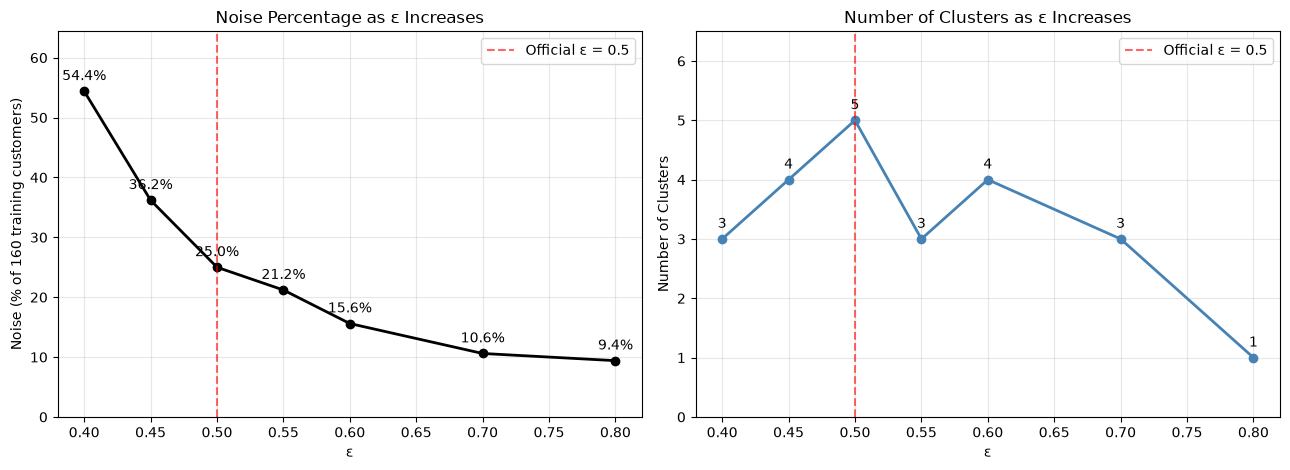

In [55]:
# Visual: noise percentage and number of clusters as eps increases
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(eps_comparison["ε"], eps_comparison["Noise %"], marker='o', color='black', linewidth=2)
for x, y in zip(eps_comparison["ε"], eps_comparison["Noise %"]):
    axes[0].annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha='center')
axes[0].axvline(best_eps, color='red', linestyle='--', alpha=0.6, label='Official ε = 0.5')
axes[0].set_xlabel('ε')
axes[0].set_ylabel('Noise (% of 160 training customers)')
axes[0].set_title('Noise Percentage as ε Increases')
axes[0].set_ylim(0, max(eps_comparison["Noise %"]) + 10)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(eps_comparison["ε"], eps_comparison["Clusters"], marker='o', color='steelblue', linewidth=2)
for x, y in zip(eps_comparison["ε"], eps_comparison["Clusters"]):
    axes[1].annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 8), ha='center')
axes[1].axvline(best_eps, color='red', linestyle='--', alpha=0.6, label='Official ε = 0.5')
axes[1].set_xlabel('ε')
axes[1].set_ylabel('Number of Clusters')
axes[1].set_title('Number of Clusters as ε Increases')
axes[1].set_ylim(0, max(eps_comparison["Clusters"]) + 1.5)
axes[1].set_yticks(range(0, max(eps_comparison["Clusters"]) + 2))
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

The second panel is included because the noise line alone hides what happens to the clusters: noise falls steadily, while the number of clusters goes up and down and then drops to 1.

The table below tracks where each of the five official clusters ends up at every ε. Each official cluster is matched to the cluster that holds most of its customers in that run. Official clusters that share the same new cluster have merged.

In [56]:
# Where do the five official clusters go at each eps?
official_ids = sorted(set(dbscan_labels) - {-1})
tracking_rows = []

for eps in eps_values:
    labels_eps = eps_runs[eps]
    destination = {}
    for cid in official_ids:
        members = labels_eps[dbscan_labels == cid]
        clustered_members = members[members != -1]
        if len(clustered_members) == 0:
            destination[cid] = "noise"
        else:
            destination[cid] = int(pd.Series(clustered_members).mode()[0])

    groups = {}
    for cid, dest in destination.items():
        groups.setdefault(dest, []).append(cid)

    descriptions = []
    for dest, cids in groups.items():
        names = " + ".join(f"{c} ({cluster_names[c]})" for c in cids)
        if dest == "noise":
            descriptions.append(f"Became noise: {names}")
        elif len(cids) > 1:
            descriptions.append(f"Merged: {names}")
    new_clusters_from_noise = len(set(labels_eps) - {-1} - {d for d in destination.values() if d != "noise"})

    tracking_rows.append({
        "ε": eps,
        "Clusters": len(set(labels_eps) - {-1}),
        "Official Clusters Kept Separate": sum(1 for d, c in groups.items() if d != "noise" and len(c) == 1),
        "Changes vs Official Model": "; ".join(descriptions) if descriptions else "None (official model)" if np.isclose(eps, best_eps) else "None",
        "New Clusters Formed Only From Official Noise": new_clusters_from_noise,
    })

cluster_tracking = pd.DataFrame(tracking_rows)
with pd.option_context('display.max_colwidth', None):
    display(cluster_tracking)

,ε,Clusters,Official Clusters Kept Separate,Changes vs Official Model,New Clusters Formed Only From Official Noise
0,0.40,3,3,Became noise: 3 (Loyal Veterans) + 4 (Premium Loyalists),0
1,0.45,4,4,Became noise: 4 (Premium Loyalists),0
2,0.50,5,5,None (official model),0
3,0.55,3,2,Merged: 1 (Frugal Mature) + 3 (Loyal Veterans) + 4 (Premium Loyalists),0
4,0.60,4,2,Merged: 1 (Frugal Mature) + 3 (Loyal Veterans) + 4 (Premium Loyalists),1
5,0.70,3,2,Merged: 1 (Frugal Mature) + 3 (Loyal Veterans) + 4 (Premium Loyalists),0
6,0.80,1,0,Merged: 0 (Young Spenders) + 1 (Frugal Mature) + 2 (New Low-Spenders) + 3 (Loyal Veterans) + 4 (Premium Loyalists),0


### What the Output Shows

- **Noise falls steadily as ε grows:** 54.4% at 0.40, 25.0% at 0.50, 15.6% at 0.60, 10.6% at 0.70, and 9.4% at 0.80.
- **The number of clusters does not fall steadily:** 3, 4, 5, 3, 4, 3, then 1. The official ε = 0.5 is the only value in this range that produces 5 clusters.
- **Below 0.5, the smaller official clusters turn into noise:** at ε = 0.45 Cluster 4 (Premium Loyalists, 7 customers) becomes noise, and at ε = 0.40 Cluster 3 (Loyal Veterans) does as well.
- **From ε = 0.55 upwards**, the official Clusters 1 (Frugal Mature), 3 (Loyal Veterans), and 4 (Premium Loyalists) merge into a single cluster. Clusters 0 (Young Spenders) and 2 (New Low-Spenders) stay separate up to ε = 0.70.
- **At ε = 0.60**, a new 5-customer cluster appears that is made up only of customers who were noise in the official model.
- **At ε = 0.80, the model collapses into one large cluster** containing 145 of the 160 training customers (90.6%), with 15 left as noise. Silhouette and Davies-Bouldin cannot be calculated with only one cluster, and the ARI against the official model drops to 0.037.
- **ε = 0.55 has stronger internal evaluation scores than ε = 0.5** (silhouette 0.5570 vs 0.4713; Davies-Bouldin 0.5815 vs 0.7833), but it merges three of the five official customer segments (Clusters 1, 3, and 4) into one cluster.
- **Silhouette and Davies-Bouldin move in both directions** across the range. The highest silhouette (0.6961, at ε = 0.40) is calculated on only 73 customers, because more than half of the training customers are noise at that ε.

The sensitivity test shows me that ε = 0.5 is a reasonable choice for this activity, but it is not the only possible answer. At 0.5 the model keeps five separate customer groups, but 25% of the customers are labelled as noise. Increasing ε lowers the amount of noise, but it also starts merging some of the customer groups together, and by 0.8 almost everyone becomes one cluster. Lowering ε makes too many customers become noise. I think 0.5 gives a useful middle ground because it keeps the most detailed customer segmentation, but the results are still somewhat sensitive to ε, especially for the smaller clusters.

## Bonus Analysis 2: What If the Highly Correlated Feature Is Removed?

*Additional Analysis (Not Required by the Lab). The official four-feature model in Parts 1 to 5 is not changed.*

**Question:** does removing `Years_Customer`, which is very strongly correlated with `Age` (r ≈ 0.98, see 2.2), materially change the DBSCAN clustering?

**Why test this:** `Age` and `Years_Customer` are different measurements, but in this dataset they carry a lot of overlapping information: older customers almost always have more years as a customer. DBSCAN groups customers by distance, and each feature adds to that distance. When two features rise and fall together, the age/tenure pattern effectively gets counted twice, so it may have more influence on who counts as "close" than income or spending does. This experiment removes `Years_Customer` to see whether that overlap actually changes the result.

**How the experiment is kept separate and fair:**

| Setting | Official Model | Three-Feature Experiment |
|---|---|---|
| Features | Annual_Income, Spending_Score, Age, Years_Customer | Annual_Income, Spending_Score, Age |
| Train/test rows | Split from 2.5 | **The same rows** (no new split) |
| Scaler | `scaler` (fitted in 2.6) | A **new** scaler, fitted on the three-feature training data only |
| MinPts | 2 × 4 = 8 | 2 × 3 = **6** |
| ε | 0.5 | Read from a **new** k-distance plot (not reused automatically) |

All new objects use a `_3f` suffix (three features) so nothing from the official model is overwritten.

In [57]:
# Bonus 2: three-feature data, using exactly the same training rows as the official model
features_3f = ['Annual_Income', 'Spending_Score', 'Age']

X_train_3f = X_train[features_3f].copy()
X_test_3f = X_test[features_3f].copy()

# New scaler, fitted on the three-feature training data only
scaler_3f = StandardScaler()
X_train_3f_scaled = scaler_3f.fit_transform(X_train_3f)

min_samples_3f = 2 * len(features_3f)   # = 6

print("Three-feature experiment")
print(f"Features: {features_3f}")
print(f"Training rows: {X_train_3f.shape[0]} (same rows as the official model: "
      f"{X_train_3f.index.equals(X_train.index)})")
print(f"Scaled training shape: {X_train_3f_scaled.shape}")
print(f"MinPts = 2 × {len(features_3f)} = {min_samples_3f}")
print()
print("Learned parameters (three-feature scaler):")
for i, col in enumerate(features_3f):
    print(f"  {col}: mean = {scaler_3f.mean_[i]:.2f}, std = {scaler_3f.scale_[i]:.2f}")

Three-feature experiment
Features: ['Annual_Income', 'Spending_Score', 'Age']
Training rows: 160 (same rows as the official model: True)
Scaled training shape: (160, 3)
MinPts = 2 × 3 = 6

Learned parameters (three-feature scaler):
  Annual_Income: mean = 257.49, std = 734.78
  Spending_Score: mean = 53.80, std = 30.17
  Age: mean = 41.91, std = 14.15


### k-Distance Plot for the Three-Feature Data (k = 6)

The same method as 3.2: for every training customer, the distance to its 6th-nearest neighbour is calculated in the new three-feature scaled space, then sorted. Distances here are not on the same scale as the four-feature plot in 3.2, because there is one fewer feature contributing to each distance.

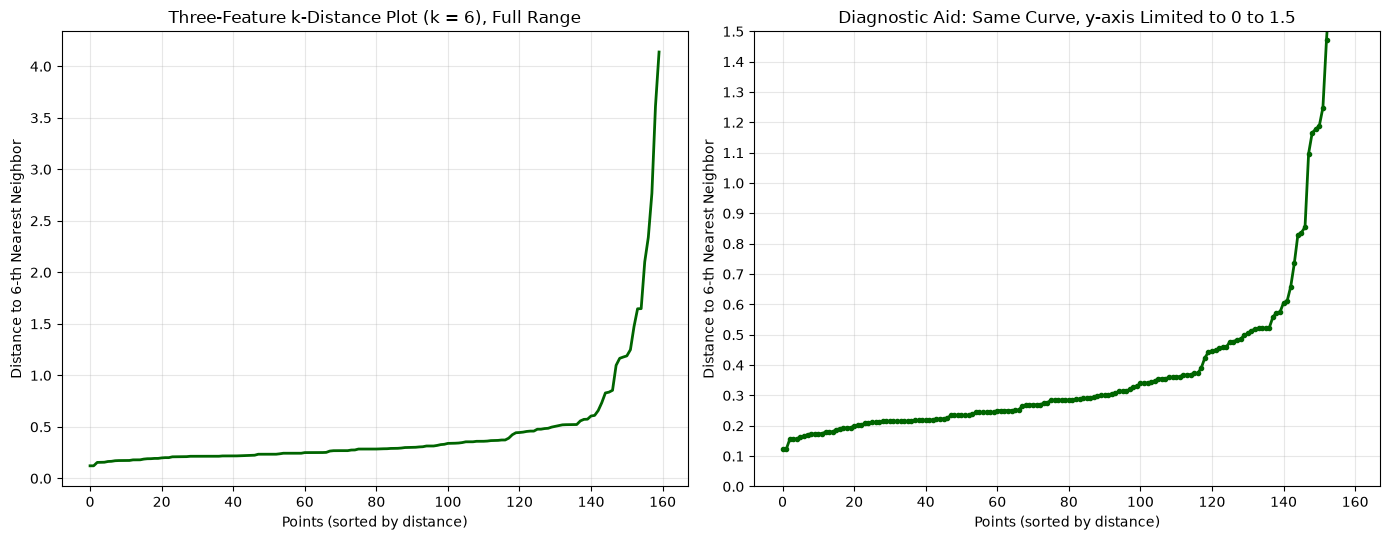

Smallest k-distance: 0.1220
Median k-distance: 0.2849
Largest k-distance: 4.1387


In [58]:
# k-distance plot for the three-feature data
k_3f = min_samples_3f  # = 6

neighbors_3f = NearestNeighbors(n_neighbors=k_3f).fit(X_train_3f_scaled)
distances_3f, _ = neighbors_3f.kneighbors(X_train_3f_scaled)
k_distances_3f = np.sort(distances_3f[:, k_3f - 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(k_distances_3f, color='darkgreen', linewidth=2)
axes[0].set_xlabel('Points (sorted by distance)')
axes[0].set_ylabel(f'Distance to {k_3f}-th Nearest Neighbor')
axes[0].set_title(f'Three-Feature k-Distance Plot (k = {k_3f}), Full Range')
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_distances_3f, color='darkgreen', linewidth=2, marker='o', markersize=3)
axes[1].set_ylim(0, 1.5)
axes[1].set_yticks(np.arange(0, 1.51, 0.1))
axes[1].set_xlabel('Points (sorted by distance)')
axes[1].set_ylabel(f'Distance to {k_3f}-th Nearest Neighbor')
axes[1].set_title('Diagnostic Aid: Same Curve, y-axis Limited to 0 to 1.5')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Smallest k-distance: {k_distances_3f.min():.4f}")
print(f"Median k-distance: {np.median(k_distances_3f):.4f}")
print(f"Largest k-distance: {k_distances_3f.max():.4f}")

In [59]:
# Percentiles and core-point counts at candidate eps values (no DBSCAN fitted here)
pct_3f = [25, 50, 75, 85, 90, 95, 100]
display(pd.DataFrame({
    "Percentile of Points": [f"{p}%" for p in pct_3f],
    "k-Distance": [round(np.percentile(k_distances_3f, p), 3) for p in pct_3f],
}))

candidate_eps_3f = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7]
pd.DataFrame({
    "Candidate ε": candidate_eps_3f,
    "Points With k-Distance ≤ ε (core points)": [int((k_distances_3f <= e).sum()) for e in candidate_eps_3f],
    "Percentage of Training Points": [f"{(k_distances_3f <= e).mean() * 100:.1f}%" for e in candidate_eps_3f],
})

,Percentile of Points,k-Distance
0,25%,0.218
1,50%,0.285
2,75%,0.444
3,85%,0.522
4,90%,0.744
5,95%,1.260
6,100%,4.139


,Candidate ε,Points With k-Distance ≤ ε (core points),Percentage of Training Points
0,0.30,91,56.9%
1,0.35,105,65.6%
2,0.40,118,73.8%
3,0.45,122,76.2%
4,0.50,130,81.2%
5,0.55,137,85.6%
6,0.60,140,87.5%
7,0.70,143,89.4%


### What the Output Shows

- The k-distances rise gradually from about 0.12 to about 0.39 across the first 118 training points (73.8%). The median is 0.285.
- There is a small step from about 0.39 to 0.42, after which the curve climbs more steeply but still fairly smoothly from about 0.42 to 0.61, covering points 119 to 142.
- The sharpest bend comes after about 0.61 to 0.74, where the distances jump to 0.83 and then climb steeply to 4.14 across the last 15 or so points.
- The curve therefore has no single clear elbow. Reasonable readings fall somewhere between about 0.4 and 0.6.
- These distances are smaller than in the four-feature plot (median 0.285 vs 0.483) because one fewer feature contributes to each distance, so the official ε = 0.5 cannot simply be carried over.

The new k-distance plot does not have one perfectly sharp elbow, but the curve starts increasing more noticeably around 0.4. I will use ε = 0.40 for the three-feature sensitivity model because it is around the first reasonable bend in the new curve. I am not trying to force this version to produce the same five clusters as the original model.

### Fit the Three-Feature DBSCAN Model

DBSCAN is fitted on the three-feature scaled training data with ε = 0.40 and MinPts = 6. The official model (`dbscan`, `dbscan_labels`) is not touched.

In [60]:
# Fit the three-feature sensitivity model
eps_3f = 0.40
dbscan_3f = DBSCAN(eps=eps_3f, min_samples=min_samples_3f)
labels_3f = dbscan_3f.fit_predict(X_train_3f_scaled)

clustered_3f = labels_3f != -1
n_clusters_3f = len(set(labels_3f[clustered_3f]))
n_noise_3f = int((~clustered_3f).sum())
sil_3f = silhouette_score(X_train_3f_scaled[clustered_3f], labels_3f[clustered_3f])
db_3f = davies_bouldin_score(X_train_3f_scaled[clustered_3f], labels_3f[clustered_3f])
ari_3f = adjusted_rand_score(dbscan_labels, labels_3f)

print("=" * 70)
print("THREE-FEATURE DBSCAN (TRAINING SET)")
print("=" * 70)
print(f"ε (eps): {eps_3f}")
print(f"MinPts (min_samples): {min_samples_3f}")
print(f"Number of clusters: {n_clusters_3f}")
print(f"Number of noise points: {n_noise_3f} ({n_noise_3f / len(labels_3f) * 100:.1f}%)")
print(f"Silhouette (excl. noise): {sil_3f:.4f}")
print(f"Davies-Bouldin (excl. noise): {db_3f:.4f}")
print(f"ARI vs official four-feature labels: {ari_3f:.3f}")

THREE-FEATURE DBSCAN (TRAINING SET)
ε (eps): 0.4
MinPts (min_samples): 6
Number of clusters: 4
Number of noise points: 28 (17.5%)
Silhouette (excl. noise): 0.5493
Davies-Bouldin (excl. noise): 0.6102
ARI vs official four-feature labels: 0.756


### Side-by-Side Comparison With the Official Model

In [61]:
# Official four-feature model vs three-feature sensitivity model
def sizes_text(labels):
    return ", ".join(str(int((labels == c).sum())) for c in sorted(set(labels) - {-1}))

feature_comparison = pd.DataFrame({
    "Measure": ["Features", "MinPts", "ε", "Clusters", "Noise customers", "Noise %",
                "Customers scored", "Silhouette (excl. noise)", "Davies-Bouldin (excl. noise)",
                "Cluster sizes", "ARI vs official labels"],
    "Official (4 features)": [
        ", ".join(features), best_min_samples, best_eps, n_clusters, n_noise,
        f"{n_noise / len(dbscan_labels) * 100:.1f}%", int(n_non_noise),
        round(dbscan_silhouette, 4), round(dbscan_db, 4), sizes_text(dbscan_labels), "baseline",
    ],
    "Three-Feature Experiment": [
        ", ".join(features_3f), min_samples_3f, eps_3f, n_clusters_3f, n_noise_3f,
        f"{n_noise_3f / len(labels_3f) * 100:.1f}%", int(clustered_3f.sum()),
        round(sil_3f, 4), round(db_3f, 4), sizes_text(labels_3f), round(ari_3f, 3),
    ],
})
with pd.option_context('display.max_colwidth', None):
    display(feature_comparison)

,Measure,Official (4 features),Three-Feature Experiment
0,Features,"Annual_Income, Spending_Score, Age, Years_Customer","Annual_Income, Spending_Score, Age"
1,MinPts,8,6
2,ε,0.5,0.4
3,Clusters,5,4
4,Noise customers,40,28
5,Noise %,25.0%,17.5%
6,Customers scored,120,132
7,Silhouette (excl. noise),0.4713,0.5493
8,Davies-Bouldin (excl. noise),0.7833,0.6102
9,Cluster sizes,"62, 19, 19, 13, 7","64, 27, 24, 17"


### How to Read This

The two models are scored in different feature spaces (four features vs three) and with different noise levels, so their silhouette and Davies-Bouldin scores describe different sets of customers measured in different ways. They show how well separated each model's own clusters are, not which feature set is correct. The ARI compares the actual groupings customer by customer: 1.0 would mean both models group every training customer the same way.

### Where Did Customers Move?

The cross-tabulation below shows every training customer's group in the official model (rows) and in the three-feature model (columns). Each cell counts customers. Official cluster names come from 4.3.1.

In [62]:
# Cross-tab: official four-feature groups vs three-feature groups
row_names = pd.Series(dbscan_labels).map(
    lambda c: "Noise (-1)" if c == -1 else f"Official {c} ({cluster_names[c]})")
col_names = pd.Series(labels_3f).map(lambda c: "Noise (-1)" if c == -1 else f"3F Cluster {c}")
movement = pd.crosstab(row_names.rename("Official 4-Feature Group"),
                       col_names.rename("Three-Feature Group"), margins=True, margins_name="Total")
movement

Three-Feature Group,3F Cluster 0,3F Cluster 1,3F Cluster 2,3F Cluster 3,Noise (-1),Total
Official 4-Feature Group,,,,,,
Noise (-1),2,5,9,0,24,40
Official 0 (Young Spenders),62,0,0,0,0,62
Official 1 (Frugal Mature),0,2,15,0,2,19
Official 2 (New Low-Spenders),0,0,0,17,2,19
Official 3 (Loyal Veterans),0,13,0,0,0,13
Official 4 (Premium Loyalists),0,7,0,0,0,7
Total,64,27,24,17,28,160


In [63]:
# Profile of each three-feature cluster and where its customers came from
df_train_3f = df_train[['Customer_ID'] + features].copy()
df_train_3f['Official'] = dbscan_labels
df_train_3f['ThreeF'] = labels_3f

rows_3f = []
for c in sorted(set(labels_3f) - {-1}):
    members = df_train_3f[df_train_3f['ThreeF'] == c]
    sources = members['Official'].value_counts()
    source_text = ", ".join(
        f"{n} from {'noise' if o == -1 else f'Official {o} ({cluster_names[o]})'}"
        for o, n in sources.items())
    rows_3f.append({
        "3F Cluster": c,
        "Customers": len(members),
        "Mean Age": round(members['Age'].mean(), 1),
        "Mean Income": round(members['Annual_Income'].mean(), 1),
        "Mean Spending": round(members['Spending_Score'].mean(), 1),
        "Mean Years (not used by this model)": round(members['Years_Customer'].mean(), 1),
        "Where Its Customers Came From": source_text,
    })

with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(rows_3f))

# Movement into and out of noise
noise_summary = pd.DataFrame({
    "Movement": ["Noise in both models",
                 "Noise in official model, clustered in three-feature model",
                 "Clustered in official model, noise in three-feature model",
                 "Clustered in both models"],
    "Customers": [int(((dbscan_labels == -1) & (labels_3f == -1)).sum()),
                  int(((dbscan_labels == -1) & (labels_3f != -1)).sum()),
                  int(((dbscan_labels != -1) & (labels_3f == -1)).sum()),
                  int(((dbscan_labels != -1) & (labels_3f != -1)).sum())],
})
noise_summary

,3F Cluster,Customers,Mean Age,Mean Income,Mean Spending,Mean Years (not used by this model),Where Its Customers Came From
0,0,64,35.5,72.0,85.1,7.1,"62 from Official 0 (Young Spenders), 2 from noise"
1,1,27,60.4,116.3,44.9,17.4,"13 from Official 3 (Loyal Veterans), 7 from Official 4 (Premium Loyalists), 5 from noise, 2 from Official 1 (Frugal Mature)"
2,2,24,45.2,63.4,23.9,11.3,"15 from Official 1 (Frugal Mature), 9 from noise"
3,3,17,26.0,32.3,19.4,3.8,17 from Official 2 (New Low-Spenders)


,Movement,Customers
0,Noise in both models,24
1,"Noise in official model, clustered in three-fe...",16
2,"Clustered in official model, noise in three-fe...",4
3,Clustered in both models,116


In [64]:
# The 4 customers who were clustered in the official model but are noise without Years_Customer
moved_to_noise = df_train_3f[(df_train_3f['Official'] != -1) & (df_train_3f['ThreeF'] == -1)].copy()
moved_to_noise['Official Cluster'] = moved_to_noise['Official'].map(lambda c: f"{c} ({cluster_names[c]})")
moved_to_noise[['Customer_ID'] + features + ['Official Cluster']].reset_index(drop=True)

,Customer_ID,Annual_Income,Spending_Score,Age,Years_Customer,Official Cluster
0,170,25,3,55,14,1 (Frugal Mature)
1,156,250,3,25,3,2 (New Low-Spenders)
2,179,50,7,58,16,1 (Frugal Mature)
3,161,350,25,21,2,2 (New Low-Spenders)


### Visual Comparison

Both models use Age and Spending Score, so the plots below show the same customers on those two features, coloured by the official model (left) and by the three-feature model (right). Noise is shown as black ×. Colours are not linked across the two panels: the same colour does not mean the same cluster.

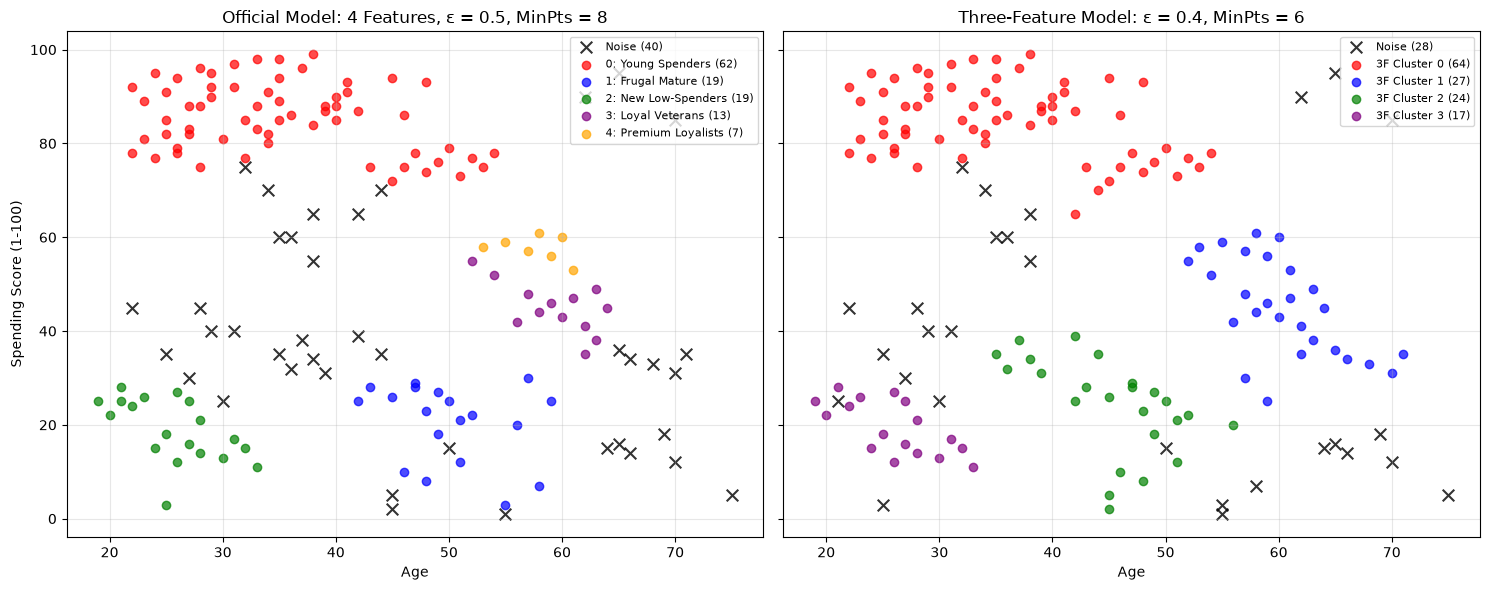

In [65]:
# Side by side: official clusters vs three-feature clusters (Age vs Spending Score)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
palette_3f = ['red', 'blue', 'green', 'purple', 'orange', 'brown']

for ax, labels, title, names in [
    (axes[0], dbscan_labels, f"Official Model: 4 Features, ε = {best_eps}, MinPts = {best_min_samples}", True),
    (axes[1], labels_3f, f"Three-Feature Model: ε = {eps_3f}, MinPts = {min_samples_3f}", False),
]:
    noise = labels == -1
    ax.scatter(X_train['Age'][noise], X_train['Spending_Score'][noise],
               c='black', marker='x', s=70, alpha=0.8, label=f'Noise ({noise.sum()})')
    for i, c in enumerate(sorted(set(labels) - {-1})):
        m = labels == c
        lab = f"{c}: {cluster_names[c]} ({m.sum()})" if names else f"3F Cluster {c} ({m.sum()})"
        ax.scatter(X_train['Age'][m], X_train['Spending_Score'][m],
                   c=palette_3f[i % len(palette_3f)], alpha=0.7, label=lab)
    ax.set_title(title)
    ax.set_xlabel('Age')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='upper right')

axes[0].set_ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

### What the Output Shows

- **Overall:** the three-feature model finds 4 clusters instead of 5 and labels 28 customers (17.5%) as noise instead of 40 (25.0%). The ARI against the official labels is 0.756.
- **Official Cluster 0 (Young Spenders) stays recognizable:** all 62 of its customers are together in 3F Cluster 0, joined by 2 customers who were noise in the official model.
- **Official Cluster 2 (New Low-Spenders) stays mostly recognizable:** 17 of its 19 customers form 3F Cluster 3. The other 2 are the customers with incomes of 250 and 350, who become noise.
- **Official Clusters 3 (Loyal Veterans) and 4 (Premium Loyalists) merge:** all 13 + 7 of their customers end up together in 3F Cluster 1, along with 5 former noise customers (ages 65 to 71, incomes 141 to 153) and 2 customers from official Cluster 1.
- **Official Cluster 1 (Frugal Mature) mostly stays together:** 15 of its 19 customers form the core of 3F Cluster 2; of the other 4, 2 join 3F Cluster 1 and 2 (Customers 170 and 179) become noise. 3F Cluster 2 also gains 9 customers who were noise in the official model (all aged 35 to 45, most with spending scores of 31 to 39).
- **Movement in and out of noise:** 16 customers who were noise in the official model join a cluster, 4 clustered customers become noise, and 24 customers are noise in both models.

Removing Years_Customer did change the clustering enough that I think the overlapping information with Age was affecting the original DBSCAN result. The three-feature model had fewer noise customers and stronger internal scores, but it also reduced the number of clusters from five to four. The biggest change was that Loyal Veterans and Premium Loyalists merged into one group instead of staying separate. Most of the larger customer groups were still recognizable, so removing Years_Customer did not completely change the structure, but it did remove some of the finer separation. I do not think that automatically makes the three-feature model better, because Years_Customer may still be adding useful information even though it is very strongly related to Age.